<a href="https://colab.research.google.com/github/Yan-cabore/Atividades_Visao_Computacional_iRede/blob/main/atividade05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 5: Análise global, local e de textura
## Aluno: Carlos Yan Matos Ferreira
---

### Definição da classe VisionUtils:

In [ ]:
class VisionUtils():

  def __init__(self):
    return

  # Lê e converte uma lista de caminhos de arquivos em imagens prontas (RGB)
  def ler_imagens(self, img_list: list, type=None):
    for i in range(len(img_list)):
      img_list[i] = cv.imread(img_list[i], cv.IMREAD_COLOR_RGB)
    return img_list

  # Inicializa uma estrutura de subplots (figura e eixos) configurada e normalizada
  def criar_figure(self, fig_name, axes_x, axes_y, fig_size):
    fig, ax = plt.subplots(axes_x, axes_y, figsize=fig_size, squeeze=False)
    fig.suptitle(fig_name)
    fig.tight_layout()
    return fig, ax

  # Preenche uma grade de eixos (subplots) exibindo as imagens correspondentes
  def preencher_figure(self, axe, img_list: list, cmap=None):
    for i, linha in enumerate(axe):
      for j, ax in enumerate(linha):
        ax.imshow(img_list[i][j], cmap=cmap)

  # Atribui títulos individuais para cada um dos eixos (gráficos) na grade
  def nomear_axes(self, axe, names: list):
    for i, linha in enumerate(axe):
      for j, ax in enumerate(linha):
        ax.set_title(names[i][j])
    return

  # Oculta as bordas e marcações visuais dos eixos para uma exibição limpa
  def remover_axis(self, axe):
    for a in axe:
      a.axis('off')
    return

  # Insere de forma sequencial uma imagem no primeiro subplot que estiver vazio
  def adicionar_imagem(self, axe, img):
    for ax in axe:
      if not ax.has_data():
        ax.imshow(img)
        break
    return

  # Extrai a contagem de tons únicos de cinza para cada imagem da lista fornecida
  def qtd_gray(self, imgs: list):
    imgs_gray = [cv.cvtColor(img, cv.COLOR_RGB2GRAY) for img in imgs]
    qtds = []
    for img_gray in imgs_gray:
      qtds.append(len(np.unique(img_gray)))
    return qtds

  # Insere ruído Gaussiano sintético à imagem com base em média e desvio padrão
  def ruido_gaussiano(self, img, media, desvio_padrao):
    noise = np.random.normal(media, desvio_padrao, img.shape)
    img_ruido = img + noise
    img_ruido = np.clip(img_ruido, 0, 255)
    return img_ruido.astype(np.uint8)

  # Insere ruído do tipo Sal e Pimenta (S&P) aleatoriamente na imagem
  def salt_and_pepper_noise(self, img, noise_rate):
    noisy_image = np.copy(img)
    min_value, max_value = 0, 255
    total_pixels = noisy_image.size
    num_noisy_pixels = int(total_pixels * noise_rate)
    noisy_pixel_indices = np.random.choice(total_pixels, num_noisy_pixels, replace=False)
    pepper_indices = noisy_pixel_indices[::2]
    noisy_image.flat[pepper_indices] = min_value
    salt_indices = noisy_pixel_indices[1::2]
    noisy_image.flat[salt_indices] = max_value
    return noisy_image

  # Calcula a transformada rápida de Fourier de 2D e centraliza o espectro de magnitude
  def fourier(self, img):
    f = np.fft.fft2(img)
    f_shift = np.fft.fftshift(f)
    mag_spec = np.log(1 + np.abs(f_shift))
    return mag_spec

* Carregamento das bibliotecas, imagens e classe `VisionUtils`

In [ ]:
import cv2 as cv
import numpy as np
import skimage as sk
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from google.colab import drive

# Instanciação da classe VisionUtils para uso nos próximos blocos
vision = VisionUtils()

## **Carregamento das imagens**

### `Classe A`




In [ ]:
uploaded = files.upload()

Saving cubo5.jpeg to cubo5.jpeg
Saving cubo4.jpeg to cubo4.jpeg
Saving cubo3.jpeg to cubo3.jpeg
Saving cubo2.jpeg to cubo2.jpeg
Saving cubo1.jpeg to cubo1.jpeg


### `Classe B`

In [ ]:
uploaded = files.upload()

Saving carta5.jpeg to carta5.jpeg
Saving carta4.jpeg to carta4.jpeg
Saving carta3.jpeg to carta3.jpeg
Saving carta2.jpeg to carta2.jpeg
Saving carta1.jpeg to carta1.jpeg


### `Imagens_extra`

In [ ]:
uploaded = files.upload()

Saving cubo2_aproximado.jpeg to cubo2_aproximado.jpeg
Saving carta4_aproximada.jpeg to carta4_aproximada.jpeg


---

# **Parte 1** - Preparação do dataset e hipóteses

## 1.1 Apresentação do dataset
**Classes presentes no dataset**:
  - `Classe A`: Imagens de um mesmo cubo mágico. O objeto foi selecionado pela diversidade de cores e formato simples.

  - `Classe B`: Imagens de algumas cartas selecionadas de um baralho. O objeto foi selecionado por apresentar um formato simples, assim como o cubo, além de ter algumas figuras boas.

  - `Imagens_extras`: Imagens que eu separei para atividades específicas, como a atividade 4, que pediu um conjunto de diversos objetos. Para essa atividade, adicionei duas novas imagens para realizar a parte 4, sendo cada imagem uma aproximação de uma imagem específica de cada classe.

**Estrutura do dataset:**

```
Dataset/
├── classe_A/
│   ├── cubo1.jpeg
│   ├── cubo2.jpeg
│   ├── cubo3.jpeg
│   ├── cubo4.jpeg
│   └── cubo5.jpeg
├── classe_B/
│   ├── carta1.jpeg
│   ├── carta2.jpeg
│   ├── carta3.jpeg
│   ├── carta4.jpeg
│   └── carta5.jpeg
└── Imagens_extra/
    ├── objetos.jpeg
    ├── cubo2_aproximado.jpeg
    └── carta4_aproximada.jpeg
```

## 1.2 Visualização das imagens

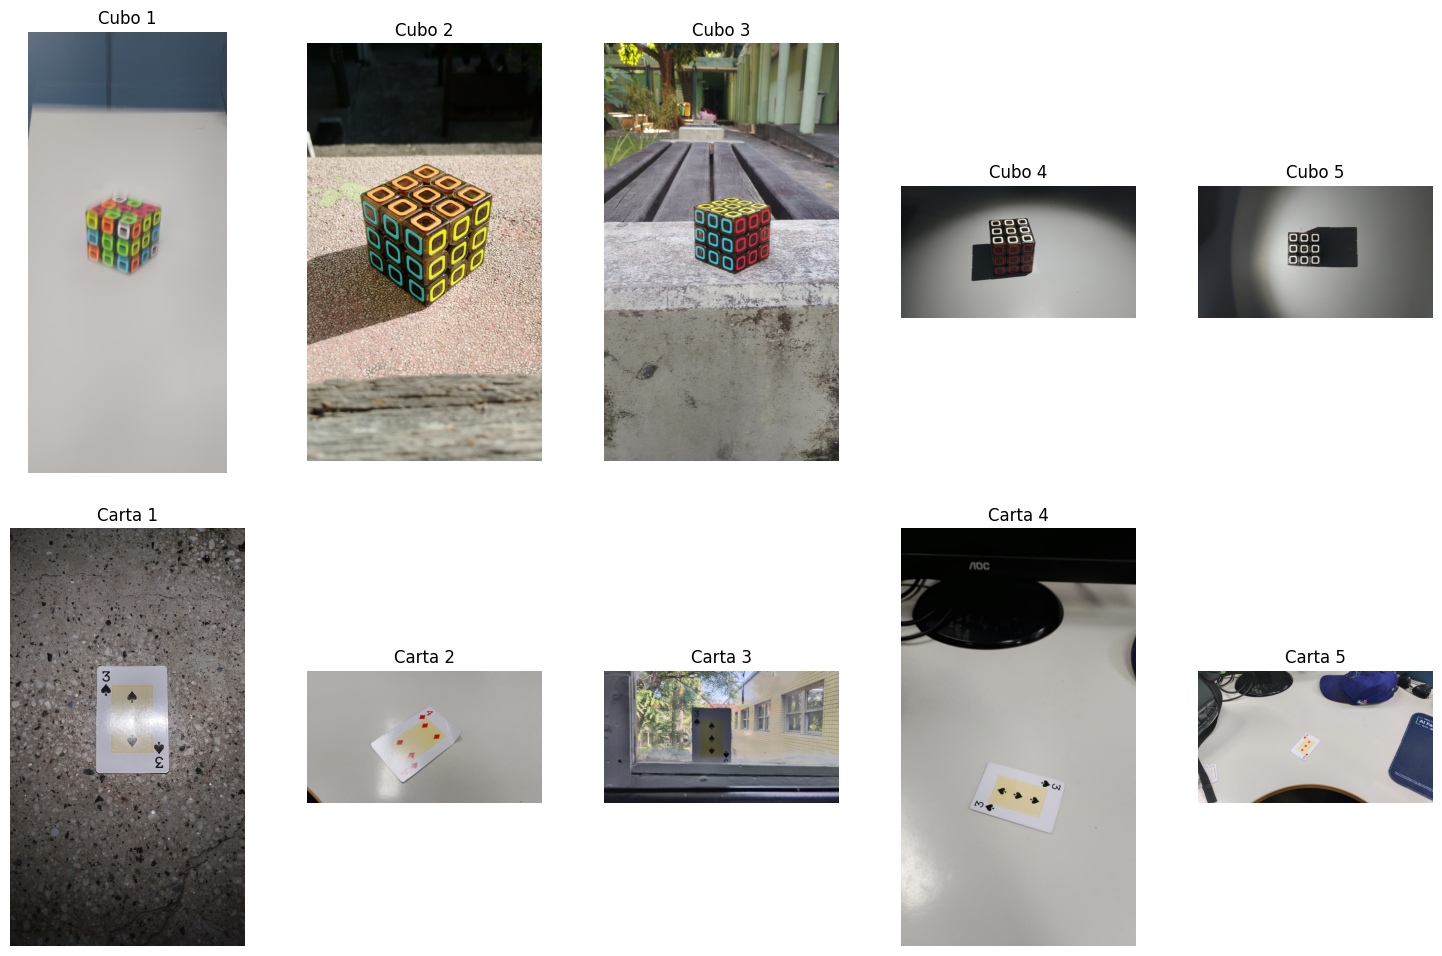

In [ ]:
vision = VisionUtils()

# Definição dos caminhos das imagens para os cubos (Classe A) e cartas (Classe B)
imgs_A = ['cubo1.jpeg', 'cubo2.jpeg', 'cubo3.jpeg', 'cubo4.jpeg', 'cubo5.jpeg']
imgs_B = ['carta1.jpeg', 'carta2.jpeg', 'carta3.jpeg', 'carta4.jpeg', 'carta5.jpeg']

# Leitura e conversão das imagens físicas para arrays RGB
vision.ler_imagens(imgs_A)
vision.ler_imagens(imgs_B)

# Agrupamento das classes e definição dos títulos dos subplots
imgs = [imgs_A, imgs_B]
nomes = [['Cubo 1', 'Cubo 2', 'Cubo 3', 'Cubo 4', 'Cubo 5'],
         ['Carta 1', 'Carta 2', 'Carta 3', 'Carta 4', 'Carta 5']]

# Geração da figura de visualização em grid (2 linhas por 5 colunas)
fig, ax = vision.criar_figure('', 2, 5, (15, 10))
vision.preencher_figure(ax, imgs, cmap='gray')
vision.nomear_axes(ax, nomes)
vision.remover_axis(ax.flatten())
plt.show()

## Registro geral das imagens:

### **Classe A**:

| Título | Local | Distância | Iluminação | Condição |
| :----: | :---: | :-------: | :--------: | :------: |
|cubo1.jpeg     |IFCE   |1 a 34cm           |Artificial            | Desfoque         |
|cubo2.jpeg        |IFCE   |1 a 16cm           |Natural            |Baixa Resolução          |
|cubo3.jpeg          |IFCE   |1 a 29cm           |Natural            |Boa          |
|cubo4.jpeg        |IFCE   |1 a 19cm          |Artificial            |Boa          |
|cubo5.jpeg      |IFCE   |1 a 17cm           |Artificial            |Baixa Resolução          |

### **Classe B**:

| Título | Local | Distância | Iluminação | Condição |
| :----: | :---: | :-------: | :--------: | :------: |
|carta1.jpeg     |IFCE   |1 a 12cm           |Artificial            |Reflexo no objeto          |
|carta2.jpeg        |IFCE   |1 a 8cm           |Artificial            |Reflexo no objeto          |
|carta3.jpeg        |IFCE   |1 a 108cm           |Natural            |Baixa Resolução          |
|carta4.jpeg        |IFCE   |1 a 18cm           |Natural            | Boa         |
|carta5.jpeg        |IFCE   |1 a 33cm           |Artificial            |Boa          |
---

## 1.3 Análise e hipóteses iniciais

### ○ Fatores de aquisição que podem influenciar a análise:
* **Iluminação**: Algumas imagens possuem iluminação natural, enquanto outras estão expostas a condições artificiais. Talvez a sombra projetada em algumas imagens acabe sendo reconhecida como parte das bordas a se detectar, especialmente nas imagens do cubo. Sendo mais específico, a carta pode ser a que mais seja influenciada por ter sofrido alguns estouros de luz devido ao uso do flash da câmera. Isso poderia acabar impactando a qualidade da detecção das figuras presentes na carta. Ademais, sua cor branca pode acabar se misturando com o fundo branco sobre o qual ela foi disposta, impedindo as bordas de serem devidamente detectadas.

* **Ângulo/Perspectiva:** O cubo mágico possui geometria tridimensional proeminente. Mudanças de perspectiva alteram as faces visíveis e as direções das linhas de contorno, o que pode acabar influenciando a etapa de matching. As cartas, sendo planas, sofrem distorções de escala e rotação dependendo da inclinação da câmera. Como ambos os objetos trabalhados possuem formatos geométricos bem definidos, creio que esses venham a ser os fatores de maior impacto.

* **Fundo (Background):** O fundo das imagens variou bastante durante o processo de captura. Sobre o fundo branco da bancada, apenas a carta corre um maior risco de ser impactada, tendo em vista a similaridade dos valores de intensidade da carta com o fundo, o que pode prejudicar a detecção de bordas da mesma. No restante das imagens, a carta foi disposta em fundos mais diferenciados. Uma ressalva para o fundo cheio de pontos brancos e pretos: creio que esse fundo vai proporcionar uma boa detecção de blobs. O cubo não vai ser tão impactado, com exceção da imagem com sombra forte, que pode acabar sendo detectada como borda também. O cubo sempre se destaca do fundo devido às suas cores vibrantes e bordas pretas. Apenas a imagem com o cubo borrado pode ser prejudicial, visto que as bordas do cubo borrado foram apagadas junto ao fundo.

### ○ Diferenças visuais esperadas entre as classes:

* **Cores:** A `Classe A` (cubo mágico) apresenta blocos sólidos de cores primárias muito bem definidas e contrastantes (azul, verde, vermelho, amarelo, branco, laranja). A `Classe B` (cartas) tende a possuir cores mais limitadas (fundo predominantemente branco com detalhes em vermelho e preto). Do ponto de vista de histogramas, a Classe A exibirá múltiplos picos correspondentes às diferentes cores vivas que a compõem, distribuídos de forma mais homogênea ao longo do espectro cromático. Já a Classe B apresentará um pico massivo na região de alta intensidade (tons de branco e cinza claro do fundo da carta) e pequenas flutuações discretas representativas dos detalhes de naipes e símbolos (vermelho e preto).

* **Formas e Bordas:** O cubo mágico exibe uma grade rígida de sub-quadrados com linhas de grade pretas bem marcadas. As cartas apresentam contornos retangulares simples com símbolos específicos (naipes) e figuras orgânicas e detalhadas no centro (no caso de valete, dama, rei). Geometricamente, a Classe A possui um padrão estrutural repetitivo de alta frequência (a grade de sub-quadrados), que atua como uma textura pseudo-periódica e gera forte assinatura de linhas ortogonais e quinas internas. A Classe B, por outro lado, possui bordas externas contínuas e isoladas, com detalhes locais (curvas e formas orgânicas complexas nas figuras internas) que concentram transições suaves de intensidade.

### ○ Qual descritor provavelmente será mais útil:

* **Histograma de Cores e Estatísticas Globais (Média e Variância):** Serão extremamente úteis para separar as classes, dado que o cubo tem uma distribuição de cores muito mais rica, saturada e diversificada em comparação ao branco predominante das cartas. Espera-se que a variância cromática e de brilho da Classe A seja significativamente superior à da Classe B, servindo como um separador linear simples e altamente eficaz entre as classes.

* **Descritores Locais (como SIFT/ORB):** Também são fortes candidatos devido à presença de cantos muito bem definidos nas quinas dos blocos do cubo e nos detalhes e símbolos geométricos (naipes) das cartas. O ORB será o método mais robusto frente às variações de rotação e escala ocorridas nas capturas das cartas. Enquanto o cubo gerará dezenas de pontos chave nas interseções internas das suas sub-faces, as cartas concentrarão pontos chave nos cantos dos naipes e nos traços complexos das faces das cartas de figuras (Rei/Valete).

* **Análise de Textura (GLCM e LBP):** Embora ambas as classes possuam superfícies relativamente lisas (plástico/papel), o padrão de grade do cubo se comporta como uma textura estruturada periódica de alta frequência. Espera-se que a homogeneidade e a energia obtidas por GLCM sejam maiores para os patches de cartas, enquanto o contraste da GLCM será muito mais proeminente no cubo mágico devido às linhas pretas marcadas que dividem as sub-faces coloridas.

# **Parte 2** - Análise global: histogramas e estatística

## 2.1 Calculando os seguintes valores de cada imagem do dataset
  - Média
  - Variância
  - Desvio Padrão
  - Entropia

In [ ]:
# Função para calcular as quatro métricas globais de intensidade da imagem
def calcular_estatisticas(img: np.ndarray):
    return [
        np.mean(img),                    # Média: indica brilho médio
        np.var(img),                     # Variância: indica dispersão global
        np.std(img),                     # Desvio Padrão: métrica de contraste global
        sk.measure.shannon_entropy(img) # Entropia: complexidade/informação espacial
    ]

estatisticas_A = []
estatisticas_B = []

# Processamento de estatísticas para cada imagem da Classe A e Classe B
for img in imgs_A:
    estatisticas_A.append(calcular_estatisticas(img))
for img in imgs_B:
    estatisticas_B.append(calcular_estatisticas(img))

# Impressão dos resultados para análise comparativa
for classe, estatisticas in [("A", estatisticas_A), ("B", estatisticas_B)]:
    for i, (media, var, std, ent) in enumerate(estatisticas):
        print(f"{classe}[{i}] -> média = {media:.2f} | var = {var:.2f} | std = {std:.2f} | entropia = {ent:.2f}")

A[0] -> média = 164.90 | var = 1858.12 | std = 43.11 | entropia = 5.83
A[1] -> média = 117.85 | var = 5929.46 | std = 77.00 | entropia = 7.74
A[2] -> média = 128.12 | var = 2050.47 | std = 45.28 | entropia = 7.38
A[3] -> média = 115.86 | var = 3844.42 | std = 62.00 | entropia = 7.29
A[4] -> média = 102.25 | var = 2376.32 | std = 48.75 | entropia = 7.48
B[0] -> média = 89.99 | var = 1843.85 | std = 42.94 | entropia = 7.34
B[1] -> média = 165.91 | var = 315.54 | std = 17.76 | entropia = 5.46
B[2] -> média = 121.39 | var = 2641.06 | std = 51.39 | entropia = 7.57
B[3] -> média = 136.98 | var = 5236.83 | std = 72.37 | entropia = 6.05
B[4] -> média = 150.35 | var = 4977.25 | std = 70.55 | entropia = 6.57


## 2.1.1 Visualização dos resultados por meio de tabela resumo

| Imagem | Média | Variância | Desvio padrão | Entropia |
|---|---|---|---|---|
| Cubo 1 | 164.90 | 1858.12 | 43.11 | 5.83 |
| Cubo 2 | 117.85 | 5929.46 | 77.00 | 7.74 |
| Cubo 3 | 128.12 | 2050.47 | 45.28 | 7.38 |
| Cubo 4 | 115.86 | 3844.42 | 62.00 | 7.29 |
| Cubo 5 | 102.25 | 2376.32 | 48.75 | 7.48 |
| Carta 1 | 89.99 | 1843.85 | 42.94 | 7.34 |
| Carta 2 | 165.91 | 315.54 | 17.76 | 5.46 |
| Carta 3 | 121.39 | 2641.06 | 51.39 | 7.57 |
| Carta 4 | 136.98 | 5236.83 | 72.37 | 6.05 |
| Carta 5 | 150.35 | 4977.25 | 70.55 | 6.57 |

## 2.1.2 Análise dos resultados

### Classe A: Cubo

- **Cubo 1:** média = 164.90 | variância = 1858.12 | desvio padrão = 43.11 | entropia = 5.83
  - Análise: Essa é a imagem na qual introduzi propositalmente um desfoque. Entre os cubos, ela tem a menor variância, o que se deve ao baixo contraste causado pelo desfoque e ao fundo claro e homogêneo, que ocupa quase toda a imagem. A entropia também é a menor entre os cubos, o que reforça que a imagem tem poucos detalhes em sua composição. Já a média foi a mais alta entre os cubos, por causa do fundo branco predominante.

- **Cubo 2:** média = 117.85 | variância = 5929.46 | desvio padrão = 77.00 | entropia = 7.74
  - Análise: A média ser menor do que a do Cubo 1 foi uma surpresa, principalmente por a imagem ter sido registrada em um ambiente natural. Acredito que isso ocorreu pela presença da área mais escura no topo, da sombra e da madeira. Esses três elementos também contribuíram para o aumento da variância, que aqui é bem maior do que na primeira imagem e a maior de todas. A entropia também aumentou bastante, sendo a de maior valor entre todas as imagens.

- **Cubo 3:** média = 128.12 | variância = 2050.47 | desvio padrão = 45.28 | entropia = 7.38
  - Análise: Imaginei que essa imagem teria uma variância maior do que a anterior, mas esse não foi o caso. O banco ocupa boa parte da imagem, gerando certa homogeneidade entre os valores da madeira e do concreto. Apesar da variância mais baixa, a entropia foi alta, o que indica que a imagem tem muitos níveis de intensidade diferentes, mesmo com um contraste global menor.

- **Cubo 4:** média = 115.86 | variância = 3844.42 | desvio padrão = 62.00 | entropia = 7.29
  - Análise: A média dessa imagem foi a segunda menor entre os cubos. Ela foi registrada com iluminação totalmente artificial, com um foco de luz no centro e as bordas escuras, além de o próprio cubo ser escuro, o que diminuiu os valores de intensidade. Ainda assim, a variância foi a segunda maior entre os cubos, algo que eu não esperava. Suponho que isso se deva aos diferentes gradientes de sombra e ao contraste entre a região iluminada e as bordas escuras, além da face vermelha do cubo. O desvio padrão acompanha a variância, então o motivo é o mesmo.

- **Cubo 5:** média = 102.25 | variância = 2376.32 | desvio padrão = 48.75 | entropia = 7.48
  - Análise: Essa foi a imagem de menor média entre os cubos, o que eu já esperava. Ao registrá-la, foquei propositalmente na face branca do cubo contra o fundo, tentando obter uma imagem que já se assemelhasse à escala de cinza. A variância foi maior do que eu esperava, e o desvio padrão (48.75) ficou acima do do Cubo 3 (45.28), o que também foi inesperado. A entropia continuou alta.

### Classe B: Carta

- **Carta 1:** média = 89.99 | variância = 1843.85 | desvio padrão = 42.94 | entropia = 7.34
  - Análise: Essa foi a imagem de menor média entre todas, o que eu já esperava, já que a carta foi registrada sobre um piso escuro, com as bordas bem sombreadas. A variância foi baixa, ficando até abaixo da do `Cubo 1`, e o desvio padrão acompanha esse comportamento. Isso se deve ao fato de o piso ocupar quase toda a imagem, o que deixa os valores de intensidade bem próximos uns dos outros. Mesmo assim, a entropia foi alta, e acredito que isso aconteceu por causa da textura do piso, cheia de pontos claros e escuros, que gera muitos níveis de intensidade diferentes sem aumentar o contraste global.

- **Carta 2:** média = 165.91 | variância = 315.54 | desvio padrão = 17.76 | entropia = 5.46
  - Análise: Essa imagem foi a de maior média e, ao mesmo tempo, a de menor variância, desvio padrão e entropia entre todas, com uma diferença muito grande para as demais. Isso já era esperado, porque a carta foi registrada sobre uma superfície branca e uniforme que ocupa praticamente toda a imagem, e a carta em si é pequena e clara. As únicas regiões de maior contraste com o restante da imagem são o pequeno ponto, que quase não pesa na imagem, o estouro de luz na carta e os pequenos pontos vermelhos da arte. De resto, pixels têm intensidades muito parecidas entre si, então há pouco contraste e poucos detalhes, o que faz dessa a imagem mais homogênea do conjunto.

- **Carta 3:** média = 121.39 | variância = 2641.06 | desvio padrão = 51.39 | entropia = 7.57
  - Análise: Essa imagem foi registrada através de uma janela, com a carta ao fundo, e a mistura de elementos claros e escuros fica evidente. Há o batente escuro da janela, a parede amarela do prédio, a vegetação e o céu mais claro. A variância ficou em um valor intermediário, o que eu achei coerente com essa mistura. A entropia foi a segunda maior de todas, só abaixo do `Cubo 2`, o que mostra que a imagem tem muitos níveis de intensidade diferentes e uma composição bem detalhada. A carta em si ocupa pouco espaço e tem pouca influência nos valores.

- **Carta 4:** média = 136.98 | variância = 5236.83 | desvio padrão = 72.37 | entropia = 6.05
  - Análise: A variância aqui foi a segunda maior de todas, atrás apenas do `Cubo 2`, e isso era esperado por causa do monitor preto no topo contra a mesa branca. A imagem tem duas regiões bem opostas, uma muito escura e outra muito clara, o que aumenta bastante a dispersão em torno da média. Por outro lado, a entropia foi baixa, e acredito que isso ocorreu porque há poucos tons intermediários, já que quase tudo é preto ou branco. Isso confirma que variância e entropia medem coisas diferentes: aqui o contraste é alto, mas a diversidade de níveis é pequena.

- **Carta 5:** média = 150.35 | variância = 4977.25 | desvio padrão = 70.55 | entropia = 6.57
  - Análise: Essa imagem é parecida com a anterior, com uma mesa branca ocupando boa parte do quadro e alguns objetos escuros e coloridos na parte superior, como o boné azul, os cabos e a borda de madeira. A média foi alta por causa da mesa clara, mas esses objetos escuros elevaram bastante a variância e o desvio padrão, que ficaram próximos dos valores da `Carta 4`. A entropia foi um pouco maior que a da imagem anterior, o que provavelmente se deve à maior variedade de objetos e cores presentes. A carta é muito pequena nessa imagem e teve pouca influência nos resultados.

### Comparação entre as classes

- **Média (brilho):** A carta teve média um pouco maior que a do cubo (132.92 contra 125.80), mas a diferença é pequena. Nas `Cartas 2, 4 e 5`, isso se deve à mesa branca, que ocupa a maior parte da imagem e domina o cálculo. As exceções são a `Carta 1` (piso escuro), que teve a menor média de todas, e a `Carta 3` (janela), com média intermediária. O cubo não teve uma média tão alta, apesar das cores vibrantes, porque nas fotos o fundo ocupa grande parte da imagem e, nos `Cubos 4 e 5`, esse fundo é escuro. Além disso, o cubo possui muitas regiões escuras, principalmente nos `Cubos 2, 4 e 5`, o que puxa a média para baixo. O `Cubo 1` (164.90), com fundo claro e desfocado, teve média mais alta que quatro das cinco cartas.

- **Variância e desvio padrão (contraste):** O cubo teve variância e desvio padrão um pouco maiores que os da carta (variância de 3211.76 contra 3002.91 e desvio de 55.23 contra 51.00), mas a diferença entre as classes é pequena. Como o desvio padrão é a raiz quadrada da variância, os dois sempre andam juntos. No cubo, o resultado se deve a imagens com regiões claras, escuras e médias, como nos `Cubos 2 e 4`. Nas cartas, a dispersão variou muito de imagem para imagem: a `Carta 2` foi muito homogênea (desvio de 17.76), enquanto as `Cartas 4 e 5` tiveram valores altos por causa de objetos escuros, como o monitor e o boné, contra a mesa branca. Em uma situação hipotética com ambos sobre fundo branco, acredito que o cubo manteria maior variância e desvio por causa das cores e das faces escuras, enquanto a carta tenderia a ser mais homogênea. Essa é apenas uma suposição, já que não foi testada.

- **Entropia (quantidade de informação/textura):** O cubo teve entropia maior (7.14 contra 6.60), o que indica maior variedade de níveis de intensidade. Isso se deve às múltiplas cores e à menor homogeneidade das imagens, além da variedade de tons e texturas dos fundos. A carta teve entropia menor na maioria das imagens, principalmente nas `Cartas 2, 4 e 5`, por causa da maior homogeneidade da mesa branca. Há exceções: o `Cubo 1` (5.83) teve entropia baixa por causa do desfoque e do fundo homogêneo, e as `Cartas 1 e 3` (7.34 e 7.57) tiveram entropia alta, acima de vários cubos, por causa da textura do piso e da composição detalhada da janela.

### Conclusão

A imagem como um todo tem um peso muito maior do que eu esperava. Não cabe apenas ao objeto definir os valores das estatísticas: o fundo também é determinante, e em muitos casos foi ele que ditou o resultado. Como `np.mean`, `np.var`, `np.std` e a entropia são calculados sobre todos os pixels, o objeto só pesa na medida em que ocupa uma proporção relevante da imagem. Nas fotos em que o cubo e a carta aparecem pequenos, como no `Cubo 1` e nas `Cartas 2 e 5`, os valores refletem principalmente a mesa, o piso ou o ambiente ao redor.

Isso ficou evidente em vários casos. A `Carta 2` teve a maior média e os menores valores de variância, desvio padrão e entropia porque a mesa branca e uniforme ocupa quase toda a imagem. A `Carta 1` teve a menor média por causa do piso escuro, e o `Cubo 2` teve a maior variância e entropia por causa da sombra, da madeira e da área escura no topo, e não pelo cubo em si. Em contrapartida, a diferença entre as classes foi pequena em todas as estatísticas, o que reforça que o conteúdo do fundo e a iluminação influenciaram tanto quanto o objeto fotografado.

Também ficou claro que cada estatística mede algo diferente. A média está ligada ao brilho geral, a variância e o desvio padrão ao contraste, e a entropia à diversidade de níveis de intensidade. Por isso uma imagem pode ter contraste alto e entropia baixa, como na `Carta 4`, onde quase tudo é preto ou branco, ou entropia alta com variância moderada, como na `Carta 1`, por causa da textura do piso.

Por fim, essas estatísticas descrevem a distribuição dos valores de intensidade, mas não dizem nada sobre onde os pixels estão nem sobre o que a imagem representa. Elas sozinhas não bastam para distinguir um cubo de uma carta, e qualquer tentativa de usá-las como característica para classificação seria muito sensível ao fundo e à iluminação. Isso mostra a importância de controlar essas condições na captura das imagens, ou de isolar o objeto de interesse, por exemplo com segmentação, antes de calcular as estatísticas.

## 2.2.1 Histogramas de intensidade

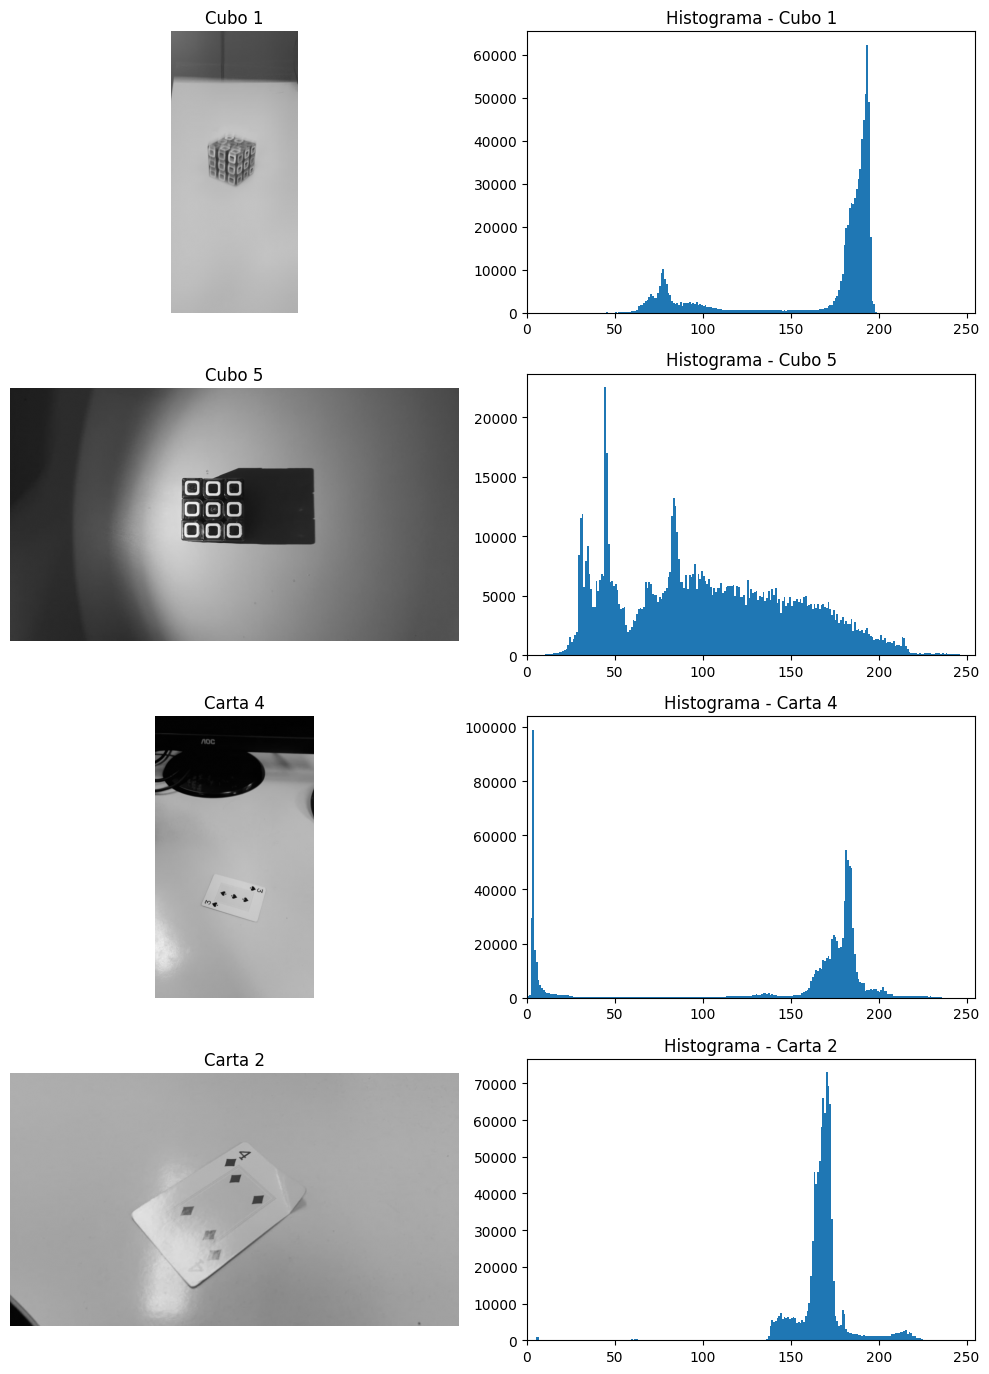

In [ ]:
# Leitura das imagens selecionadas em escala de cinza para análise de picos de intensidade
cubo1 = cv.imread('cubo1.jpeg', cv.IMREAD_GRAYSCALE)
cubo5 = cv.imread('cubo5.jpeg', cv.IMREAD_GRAYSCALE)
carta4 = cv.imread('carta4.jpeg', cv.IMREAD_GRAYSCALE)
carta2 = cv.imread('carta2.jpeg', cv.IMREAD_GRAYSCALE)

fig, ax = vision.criar_figure('', 4, 2, fig_size=(10, 14))

# Configuração dos plots da imagem vs. seu respectivo histograma de 256 bins
# Cubo 1
ax[0, 0].imshow(cubo1, cmap="gray", vmin=0, vmax=255)
ax[0, 0].set_title("Cubo 1")
ax[0, 0].axis("off")
ax[0, 1].hist(cubo1.ravel(), bins=256, range=(0, 256))
ax[0, 1].set_title("Histograma - Cubo 1")
ax[0, 1].set_xlim(0, 255)

# Cubo 5
ax[1, 0].imshow(cubo5, cmap="gray", vmin=0, vmax=255)
ax[1, 0].set_title("Cubo 5")
ax[1, 0].axis("off")
ax[1, 1].hist(cubo5.ravel(), bins=256, range=(0, 256))
ax[1, 1].set_title("Histograma - Cubo 5")
ax[1, 1].set_xlim(0, 255)

# Carta 4
ax[2, 0].imshow(carta4, cmap="gray", vmin=0, vmax=255)
ax[2, 0].set_title("Carta 4")
ax[2, 0].axis("off")
ax[2, 1].hist(carta4.ravel(), bins=256, range=(0, 256))
ax[2, 1].set_title("Histograma - Carta 4")
ax[2, 1].set_xlim(0, 255)

# Carta 2
ax[3, 0].imshow(carta2, cmap="gray", vmin=0, vmax=255)
ax[3, 0].set_title("Carta 2")
ax[3, 0].axis("off")
ax[3, 1].hist(carta2.ravel(), bins=256, range=(0, 256))
ax[3, 1].set_title("Histograma - Carta 2")
ax[3, 1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

## 2.2.2 Histogramas de cor (RGB)

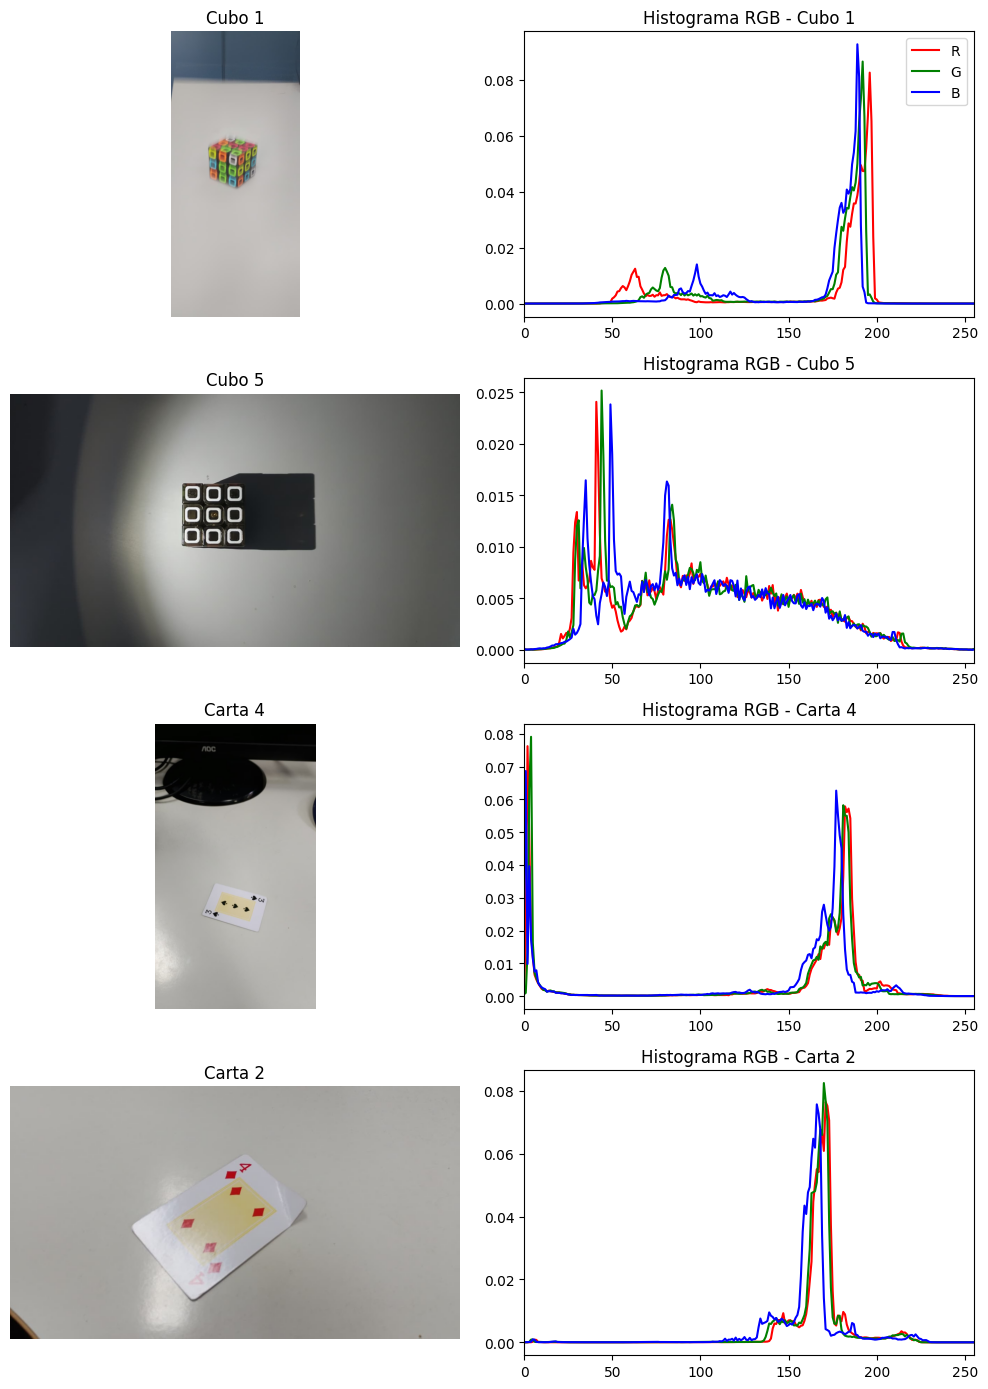

In [ ]:
# Dicionário com caminhos de imagens selecionadas
dataset = [("Cubo 1", 'cubo1.jpeg'),
           ("Cubo 5", 'cubo5.jpeg'),
           ("Carta 4", 'carta4.jpeg'),
           ("Carta 2", 'carta2.jpeg')]

fig, ax = plt.subplots(4, 2, figsize=(10, 14))

# Iteração para extrair e plotar histogramas normalizados de cores (R, G e B)
for linha, (nome, f) in enumerate(dataset):
    img = cv.cvtColor(cv.imread(f), cv.COLOR_BGR2RGB)
    total = img.shape[0] * img.shape[1]  # Cálculo do número total de pixels

    # Coluna 0: Exibe a imagem em formato colorido original
    ax[linha, 0].imshow(img)
    ax[linha, 0].set_title(nome)
    ax[linha, 0].axis("off")

    # Coluna 1: Calcula e plota a frequência relativa para cada canal de cor (R, G, B)
    for i, c in enumerate(["r", "g", "b"]):
        hist = cv.calcHist([img], [i], None, [256], [0, 256])
        ax[linha, 1].plot(hist / total, color=c, label=c.upper())

    ax[linha, 1].set_title(f"Histograma RGB - {nome}")
    ax[linha, 1].set_xlim(0, 255)

ax[0, 1].legend()
plt.tight_layout()
plt.show()

## 2.2.3 Análise dos resultados

### **Classe A: Cubo Mágico**
* **Onde a imagem concentra mais pixels (Histograma de intensidade)**
  * *Cubo 1:* A maior concentração de pixels está nos valores altos de intensidade, entre 180 e 200 (pico em torno de 190). A quantidade de pixels nessa faixa é muito alta em relação ao resto da imagem, o que indica homogeneidade, e corresponde à bancada clara sobre a qual o cubo está, que ocupa quase toda a imagem. Existe uma segunda concentração, bem menor, entre 50 e 100 (pico próximo a 80), que acredito ser o fundo mais escuro e azulado no topo da imagem. Entre esses dois grupos, de 100 a 170, há uma quantidade pequena e bem distribuída de pixels, que provavelmente vem do cubo: ele possui múltiplas cores, mas ocupa uma área muito pequena e ainda está desfocado.

  * *Cubo 5:* Os pixels ficaram bem mais distribuídos no histograma, o que pode ser explicado pelo gradiente de iluminação da imagem, com o foco de luz no centro e as bordas escuras. Os picos mais altos estão entre 30 e 50, com o maior próximo a 45. Eles podem ter sido causados pelas bordas escurecidas da imagem (principalmente a esquerda), pelas faces pretas do cubo e pela sombra que ele projeta. Há ainda um pico próximo a 80 e uma região larga e quase plana entre 60 e 180, que representa a transição de luz do fundo. Os valores acima de 200 são poucos e refletem a região mais iluminada ao redor do cubo e as bordas brancas dos quadrados.

* **Existe canal de cor dominante?**
  * *Cubo 1:* Os canais ficaram muito próximos entre si e não há um canal dominante. Na região da bancada (próximo a 190), as três curvas praticamente se sobrepõem, o que reflete a cor quase neutra da superfície. O vermelho aparece um pouco deslocado para a direita e o azul tem o pico mais alto, mas isso indica apenas uma distribuição mais concentrada, e não mais pixels azuis, já que os três canais têm o mesmo número de pixels. Na região escura (50 a 120) os canais se separam: o vermelho fica em torno de 63, o verde em torno de 80 e o azul em torno de 97. Como o azul tem os valores mais altos, isso é coerente com o fundo azulado do topo da imagem. Já as cores do cubo quase não aparecem, por ele ocupar uma área muito pequena.

  * *Cubo 5:* Aqui os canais estão muito próximos, quase sobrepostos em boa parte do histograma. O verde teve o pico mais alto (próximo a 45), mas por uma diferença mínima em relação ao vermelho. O azul se separa um pouco nas regiões escuras, com picos próximos a 35 e 50, o que sugere sombras levemente azuladas. Como tentei deixar a imagem o mais sem cor possível ao registrá-la, essa proximidade já era esperada.

* **As imagens da mesma classe apresentam comportamento parecido?**
  * *Resposta:* Não. O `Cubo 1` tem um histograma estreito, com um pico dominante na faixa clara e um pico menor na escura, enquanto o `Cubo 5` tem uma distribuição larga, com vários picos entre 30 e 215. Isso acompanha as estatísticas calculadas (média de 164.90 contra 102.25 e entropia de 5.83 contra 7.48). O que elas têm em comum é que os canais de cor ficaram próximos e que o cubo não aparece como um pico próprio, e sim diluído no fundo. A diferença entre as duas vem da bancada e da iluminação, e não do objeto.

---

### **Classe B: Cartas de Baralho**
* **Onde a imagem concentra mais pixels (Histograma de intensidade)**
  * *Carta 4:* A maior quantidade de pixels está próxima ao valor 0, o que pode ser facilmente atribuído ao monitor preto no topo da imagem. Fora isso, existe um pico forte entre 170 e 190, associado à bancada. Como a carta é pequena em relação ao fundo, ela tem pouco peso no histograma, mas os valores próximos de 200 e acima, que aparecem em pequena quantidade, podem representar sua composição.

  * *Carta 2:* Essa foi a imagem mais homogênea. Perceba a alta quantidade de pixels concentrada em um pico estreito próximo a 170, que corresponde à bancada. Há também um patamar menor entre 140 e 160, provavelmente por variações de iluminação na própria bancada. Os valores entre 200 e 225 formam uma pequena elevação, que pode ser a carta em si, mais clara que a bancada, junto com o reflexo de luz. Não chega a ser um estouro de luz, já que os valores não alcançam 255. Existe ainda uma concentração quase imperceptível próxima de 0, que se deve à pequena parte escura no canto inferior esquerdo da imagem. Como eu disse numa análise passada, ela quase não tem peso, mas o histograma mostra que ainda tem alguma influência.

* **Existe canal de cor dominante?**
  * *Carta 4:* Mais uma vez, a imagem foi influenciada pelo monitor preto no topo, que fez os três canais se sobreporem na região escura. Nessa região o verde tem o pico mais alto, mas por uma diferença muito pequena. No pico da bancada, o azul é o mais alto e aparece levemente deslocado para a esquerda em relação ao vermelho e ao verde, o que indica uma bancada com tom ligeiramente amarelado. Não há, portanto, um canal dominante.

  * *Carta 2:* Os canais tiveram valores muito próximos, tendo em vista que a imagem é homogênea. O verde teve o pico mais alto, o que me surpreendeu, e o azul aparece um pouco deslocado para a esquerda, como na `Carta 4`. Isso sugere uma bancada levemente amarelada e pode ter relação com o tom amarelado da carta. As cores vermelhas dos naipes não tiveram influência perceptível no final, porque ocupam uma área muito pequena.

* **As imagens da mesma classe apresentam comportamento parecido?**
  * *Resposta:* Mais do que no caso dos cubos, mas apenas em parte. As duas cartas têm um pico forte na faixa clara (entre 170 e 190 na `Carta 4` e próximo a 170 na `Carta 2`), pois foram registradas sobre a mesma bancada branca. A diferença é que a `Carta 4` tem um segundo pico enorme próximo a 0, por causa do monitor, e a `Carta 2` tem um único pico. Em ambas os canais ficaram próximos, com o azul levemente deslocado. Essa semelhança vem da bancada, e não da carta, que quase não aparece nos histogramas.

---

### **Conclusão Comparativa**
* **O histograma ajudou a separar as classes?**
  * *Resposta:* Não. As imagens de uma mesma classe nem sempre se parecem entre si (o `Cubo 1` e o `Cubo 5` são muito diferentes), enquanto imagens de classes diferentes podem se parecer. O `Cubo 1` e as duas cartas têm um pico dominante na faixa clara, que vem da bancada de cada uma. Os canais de cor também ficaram próximos em todas as imagens, sem um canal dominante que caracterizasse alguma classe. O histograma descreve a distribuição das intensidades da imagem inteira, sem informar o formato nem a posição do objeto, e como o cubo e a carta ocupam pouca área, ele acaba refletindo o fundo e a iluminação. Acredito que, se os dois objetos fossem registrados sobre a mesma bancada, os histogramas ficariam ainda mais parecidos, embora isso seja uma suposição que não testei. Como analisei apenas duas imagens por classe, essa conclusão também tem alcance limitado.

## 2.3 Análise de imagem derivada das anteriores

In [ ]:
# Leitura em escala de cinza para as duas imagens selecionadas
gray_1 = cv.imread('cubo1.jpeg', cv.IMREAD_GRAYSCALE)
gray_2 = cv.imread('carta4.jpeg', cv.IMREAD_GRAYSCALE)

# Quantização: reduz de 256 para 64 níveis (dividindo por 4 e multiplicando de volta)
qtd64_1 = (gray_1 // 4) * 4
qtd64_2 = (gray_2 // 4) * 4

# Cálculo das medidas de Entropia de Shannon (antes vs. depois do agrupamento)
entropia_antes_1 = sk.measure.shannon_entropy(gray_1)
entropia_antes_2 = sk.measure.shannon_entropy(gray_2)

entropia_depois_1 = sk.measure.shannon_entropy(qtd64_1)
entropia_depois_2 = sk.measure.shannon_entropy(qtd64_2)

# Exibição das métricas para avaliar a perda de informação espectral
print(f"Cubo 1 - Entropia antes: {entropia_antes_1:.4f} | Entropia depois (64 níveis): {entropia_depois_1:.4f}")
print(f"Carta 4 - Entropia antes: {entropia_antes_2:.4f} | Entropia depois (64 níveis): {entropia_depois_2:.4f}")

Cubo 1 - Entropia antes: 5.5221 | Entropia depois (64 níveis): 3.5693
Carta 4 - Entropia antes: 5.8018 | Entropia depois (64 níveis): 4.0054


### Histograma de intensidade

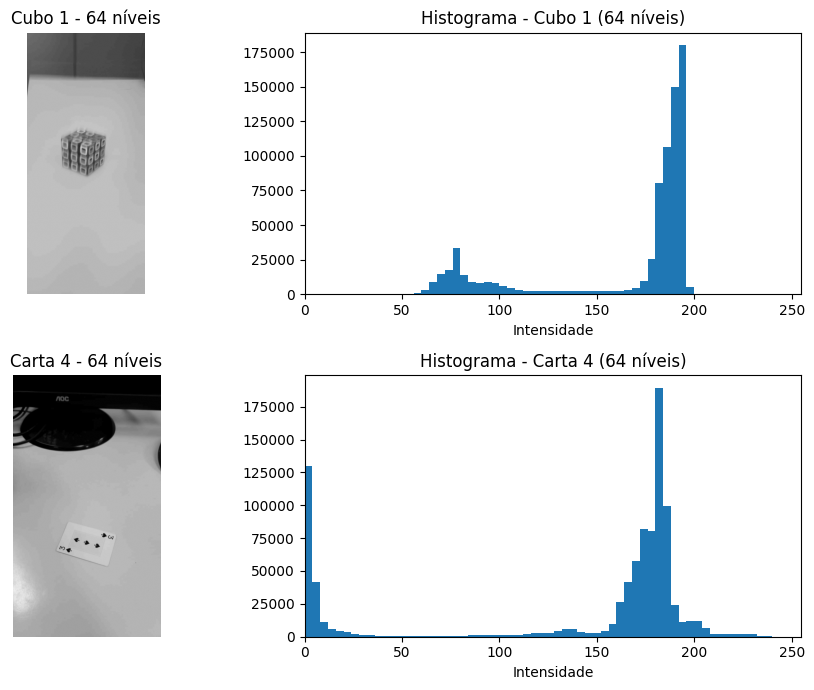

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))

# Configuração para Cubo 1 quantizado em 64 níveis de intensidade
ax[0, 0].imshow(qtd64_1, cmap="gray", vmin=0, vmax=255)
ax[0, 0].set_title("Cubo 1 - 64 níveis")
ax[0, 0].axis("off")
ax[0, 1].hist(qtd64_1.ravel(), bins=64, range=(0, 256))
ax[0, 1].set_title("Histograma - Cubo 1 (64 níveis)")
ax[0, 1].set_xlim(0, 255)
ax[0, 1].set_xlabel("Intensidade")

# Configuração para Carta 4 quantizada em 64 níveis de intensidade
ax[1, 0].imshow(qtd64_2, cmap="gray", vmin=0, vmax=255)
ax[1, 0].set_title("Carta 4 - 64 níveis")
ax[1, 0].axis("off")
ax[1, 1].hist(qtd64_2.ravel(), bins=64, range=(0, 256))
ax[1, 1].set_title("Histograma - Carta 4 (64 níveis)")
ax[1, 1].set_xlim(0, 255)
ax[1, 1].set_xlabel("Intensidade")

plt.tight_layout()
plt.show()

### Histograma de cores

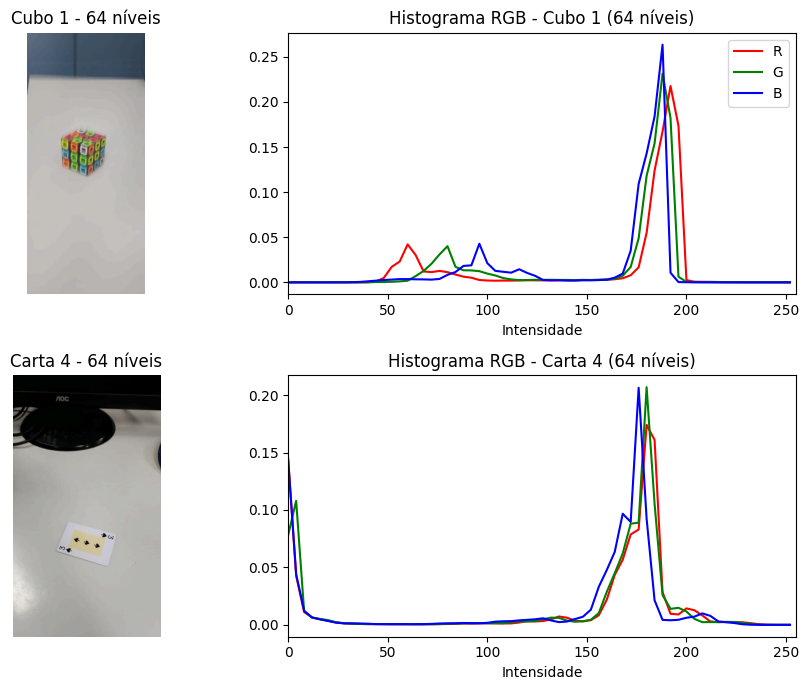

In [ ]:
cubo1_rgb = cv.cvtColor(cv.imread('cubo1.jpeg'), cv.COLOR_BGR2RGB)
carta4_rgb = cv.cvtColor(cv.imread('carta4.jpeg'), cv.COLOR_BGR2RGB)

# Aplicação de quantização uniforme de 64 níveis em cada canal de cor (R, G, B)
qtd64_rgb_1 = (cubo1_rgb // 4) * 4
qtd64_rgb_2 = (carta4_rgb // 4) * 4

fig, ax = plt.subplots(2, 2, figsize=(10, 7))

for linha, (nome, img) in enumerate([("Cubo 1", qtd64_rgb_1),
                                     ("Carta 4", qtd64_rgb_2)]):
    total = img.shape[0] * img.shape[1]

    # Coluna 0: Exibe a imagem quantizada em cores resultante
    ax[linha, 0].imshow(img)
    ax[linha, 0].set_title(f"{nome} - 64 níveis")
    ax[linha, 0].axis("off")

    # Coluna 1: Desenha os histogramas com bins agrupados para os canais RGB
    for i, c in enumerate(["r", "g", "b"]):
        hist = cv.calcHist([img], [i], None, [64], [0, 256])
        ax[linha, 1].plot(np.arange(0, 256, 4), hist / total, color=c, label=c.upper())

    ax[linha, 1].set_title(f"Histograma RGB - {nome} (64 níveis)")
    ax[linha, 1].set_xlim(0, 255)
    ax[linha, 1].set_xlabel("Intensidade")

ax[0, 1].legend()
plt.tight_layout()
plt.show()

## 2.3.1 Análise comparativa

### **Classe A: Cubo Mágico**
* **O histograma mudou muito?**
  * *Resposta:* No. O formato geral se manteve praticamente igual ao da imagem original. O pico principal continua próximo a 190, referente à bancada, e o pico menor próximo a 80 também permaneceu no mesmo lugar, assim como a região plana entre 100 e 170. A diferença está na granularidade: como os valores foram agrupados de quatro em quatro, o histograma ficou em degraus e os picos aparecem mais largos. No histograma de cores, os canais continuam separados na região escura, com o vermelho próximo a 60, o verde próximo a 80 e o azul próximo a 95, o que mostra que a relação entre eles não foi alterada. As curvas ficaram mais angulosas por terem menos pontos, mas sem mudança na interpretação. Vale lembrar que, como os bins agora são mais largos, a altura dos picos não é diretamente comparável com a do histograma original.

* **A entropia caiu ou aumentou?**
  * *Resposta:* Caiu, de **5.52** para **3.57**. Como a quantização realizada por `(img // 4) * 4` agrupa quatro níveis de intensidade vizinhos em um único nível, era esperado que a entropia diminuísse. Agrupar quatro níveis pode reduzir a incerteza em até 2 bits ($log_2(4) = 2$), de forma que essa redução de aproximadamente 1.95 bit foi bastante significativa e condizente com o processo matemático, embora a silhueta do histograma tenha se preservado.

* **Houve perda perceptível de informação útil?**
  * *Resposta:* Não. A olho nu, a imagem quantizada é praticamente idêntica à original, e o cubo continua com o mesmo formato e com suas faces distinguíveis, tanto em cinza quanto em cores. Só consigo notar leves manchas no fundo, que aparecem por ser uma região de gradiente suave e desfocada, onde o agrupamento dos níveis pode gerar faixas. Como o fundo não é a informação de interesse, essa perda não atrapalha. Ainda assim, a quantização é irreversível, já que não é possível recuperar os níveis originais depois de agrupá-los.

---

### **Classe B: Cartas de Baralho**
* **O histograma mudou muito?**
  * *Resposta:* Também não. Os dois picos principais continuaram nos mesmos lugares: um próximo a 0, referente ao monitor preto, e outro entre 170 e 190, referente à bancada. A pequena elevação próxima a 135 e a região de baixa quantidade entre 20 e 120 também se mantiveram. O que mudou foi apenas a granularidade, com barras mais largas e picos mais altos, já que quatro níveis passaram a contar como um só. No histograma de cores, os três canais continuam sobrepostos na região escura e o azul continua levemente deslocado para a esquerda no pico da bancada, então a análise de canais feita antes continua valendo.

* **A entropia caiu ou aumentou?**
  * *Resposta:* Caiu, de **5.80** para **4.01**. Assim como no cubo, essa queda era esperada e foi expressiva (uma redução de cerca de 1.80 bit). Pelo mesmo princípio de agrupamento de quatro intensidades vizinhas em uma única representação binária, a perda de quase 2 bits de informação espectral reflete perfeitamente a simplificação do sinal original promovida pela quantização.

* **Houve perda perceptível de informação útil?**
  * *Resposta:* Não. A carta continua visível sobre a bancada, e o número e o naipe ainda podem ser distinguidos. Por ser uma imagem dominada por regiões homogêneas, com poucos detalhes, a quantização para 64 níveis teve pouco efeito. A perda aparece só nos tons muito próximos, que foram agrupados, e eles não eram relevantes aqui. Acredito que uma quantização mais agressiva (por exemplo, 8 ou 16 níveis) seria necessária para que a perda ficasse evidente, mas isso não foi testado.

# **Parte 3** - Análise local: keypoints, descritores e matching

## 3.1 Keypoints

## 3.1.1 Shi-Tomasi

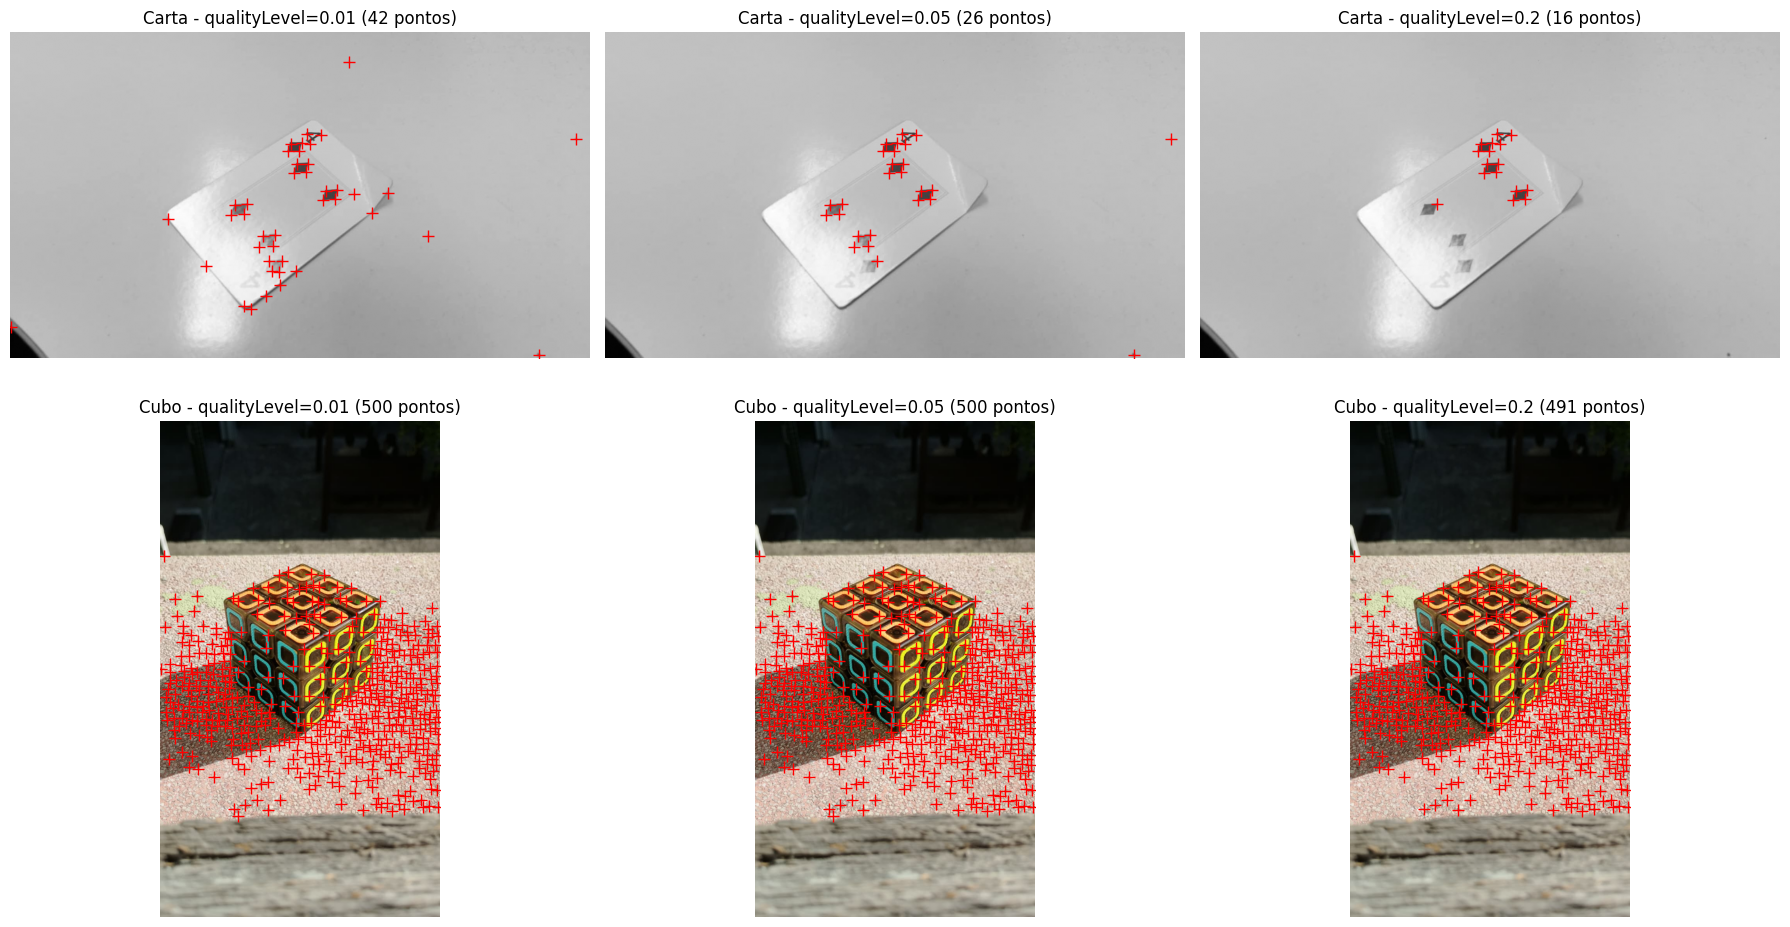

In [ ]:
carta_gray = carta2
cubo_color = cv.cvtColor(cv.imread("cubo2.jpeg"), cv.COLOR_BGR2RGB)
cubo_gray = cv.cvtColor(cubo_color, cv.COLOR_RGB2GRAY)

# Parâmetros fixos (só o qualityLevel varia)
MAX_CORNERS = 500
MIN_DISTANCE = 15
BLOCK_SIZE = 5

niveis = [0.01, 0.05, 0.2]

objetos = [
    ("Carta", carta_gray, carta_gray, "gray"),
    ("Cubo", cubo_gray, cubo_color, None),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for linha, (nome, img_gray, img_exibir, cmap) in enumerate(objetos):
    for coluna, q in enumerate(niveis):
        coords = cv.goodFeaturesToTrack(
            img_gray,
            maxCorners=MAX_CORNERS,
            qualityLevel=q,
            minDistance=MIN_DISTANCE,
            blockSize=BLOCK_SIZE
        )

        ax = axes[linha, coluna]
        ax.imshow(img_exibir, cmap=cmap)

        if coords is not None:
            coords = coords.reshape(-1, 2)
            ax.plot(coords[:, 0], coords[:, 1], "r+", markersize=8)
            qtd = len(coords)
        else:
            qtd = 0

        ax.set_title(f"{nome} - qualityLevel={q} ({qtd} pontos)")
        ax.axis("off")

plt.tight_layout()
plt.show()

### **Análise dos resultados: variação do `qualityLevel` no Shi-Tomasi**

Para justificar a escolha do `qualityLevel`, testei três valores (`0.01`, `0.05` e `0.2`), mantendo fixos `maxCorners=500`, `minDistance=15` e `blockSize=5`. Assim, qualquer diferença entre as colunas vem apenas do limiar. O critério que usei foi: **cantos sobre o objeto de interesse e poucos pontos no fundo**.

* **Carta:**
  * *`qualityLevel=0.01` (42 pontos):* Foi o valor com mais pontos detectados, por ser o menos criterioso. Além dos naipes, ele aceitou cantos fracos, como pontos na bancada (topo, borda direita e borda inferior), ao longo das bordas da carta e na região do reflexo de luz. Muitos desses pontos não representam nada relevante, então o resultado ficou poluído. Ainda assim, fiquei bastante surpreso com a qualidade da detecção dos naipes, e isso se repetiu nos outros valores. Perceba, porém, que o estouro de luz na parte inferior da carta impediu a detecção completa dos naipes dessa região e do número 4. Um filtro como o da mediana poderia atenuar esse efeito, mas acredito que ele também poderia prejudicar a presença dos cantos na imagem. Isso não foi testado.

  * *`qualityLevel=0.05` (26 pontos):* Aqui os pontos ficaram concentrados nos naipes, e a quantidade de ruído foi bem menor, com apenas 2 pontos que não pertenciam ao objeto, um na borda direita e outro na borda inferior. O estouro de luz ainda prejudicou a detecção: do naipe de baixo, apenas uma parte foi detectada. Um `qualityLevel` ainda menor talvez conseguisse detectá-lo por completo, mas o ruído aumentaria com certeza.

  * *`qualityLevel=0.2` (16 pontos):* Esse valor eliminou todo o ruído da bancada, mas foi rígido demais. Perceba que ele manteve só os três naipes de maior contraste (os escuros do topo e da direita) e perdeu os naipes de baixo, que têm menos contraste com a carta. A informação útil começou a ser descartada junto com o ruído.
  
  * *Melhor valor:* **0.05**. Ele foi o ponto de equilíbrio entre os dois extremos, mantendo os naipes com pouquíssimo ruído. O naipe de baixo ficou incompleto, mas o problema não foi o valor escolhido: esse naipe estava tão bem posicionado quanto os outros, e o que prejudicou a detecção foi o estouro de luz. O 0.2 é mais limpo, mas incompleto, e o 0.01 é mais completo, mas sujo.

* **Cubo:**
  * *`qualityLevel=0.01` (500 pontos) e `0.05` (500 pontos):* Os dois bateram no limite de `maxCorners`, e os resultados ficaram praticamente iguais. A grande maioria dos pontos está no chão, à direita e abaixo do cubo e na região da sombra, onde a superfície é granulada. Sobre o cubo, os pontos aparecem nas bordas dos quadrados coloridos. No fim, o método conseguiu encontrar os cantos de cada quadrado do cubo, mas o resultado foi muito ruidoso devido à textura da superfície sobre a qual o cubo está.

  * *`qualityLevel=0.2` (491 pontos):* Mesmo com o limiar vinte vezes maior que o primeiro, o número de pontos quase não caiu e o chão continuou cheio. Isso mostra que os grãos do chão têm resposta tão forte quanto as bordas do cubo, já que o `qualityLevel` é relativo ao melhor canto da imagem e os grãos passam por ele sem dificuldade.

  * *Melhor valor:* **0.2**, mas por uma diferença muito pequena. Foi o único em que o limiar chegou a atuar (491 está abaixo do teto de 500), então é o que menos aceita cantos fracos. Ainda assim, nenhum dos três cumpriu o critério, porque o fundo continuou dominando a detecção.

* **Comparação:** O melhor valor não foi o mesmo para os dois objetos. Na carta, o `qualityLevel` fez diferença e permitiu separar naipes de ruído. No cubo, ele praticamente não alterou o resultado, porque o problema é a textura do fundo, e não um limiar mal ajustado. Isso reforça o que já havia aparecido nas estatísticas e nos histogramas: o fundo pesa tanto quanto o objeto. Acredito que, para o cubo, seria preciso mexer em outros parâmetros, como aumentar o `blockSize`, suavizar a imagem antes da detecção ou restringir a análise à região do cubo, mas isso não foi testado. Também vale lembrar que, com `maxCorners=500`, os dois primeiros testes do cubo atingiram o teto, então a diferença real entre eles pode estar escondida.

## 3.1.2 Detecção de blobs

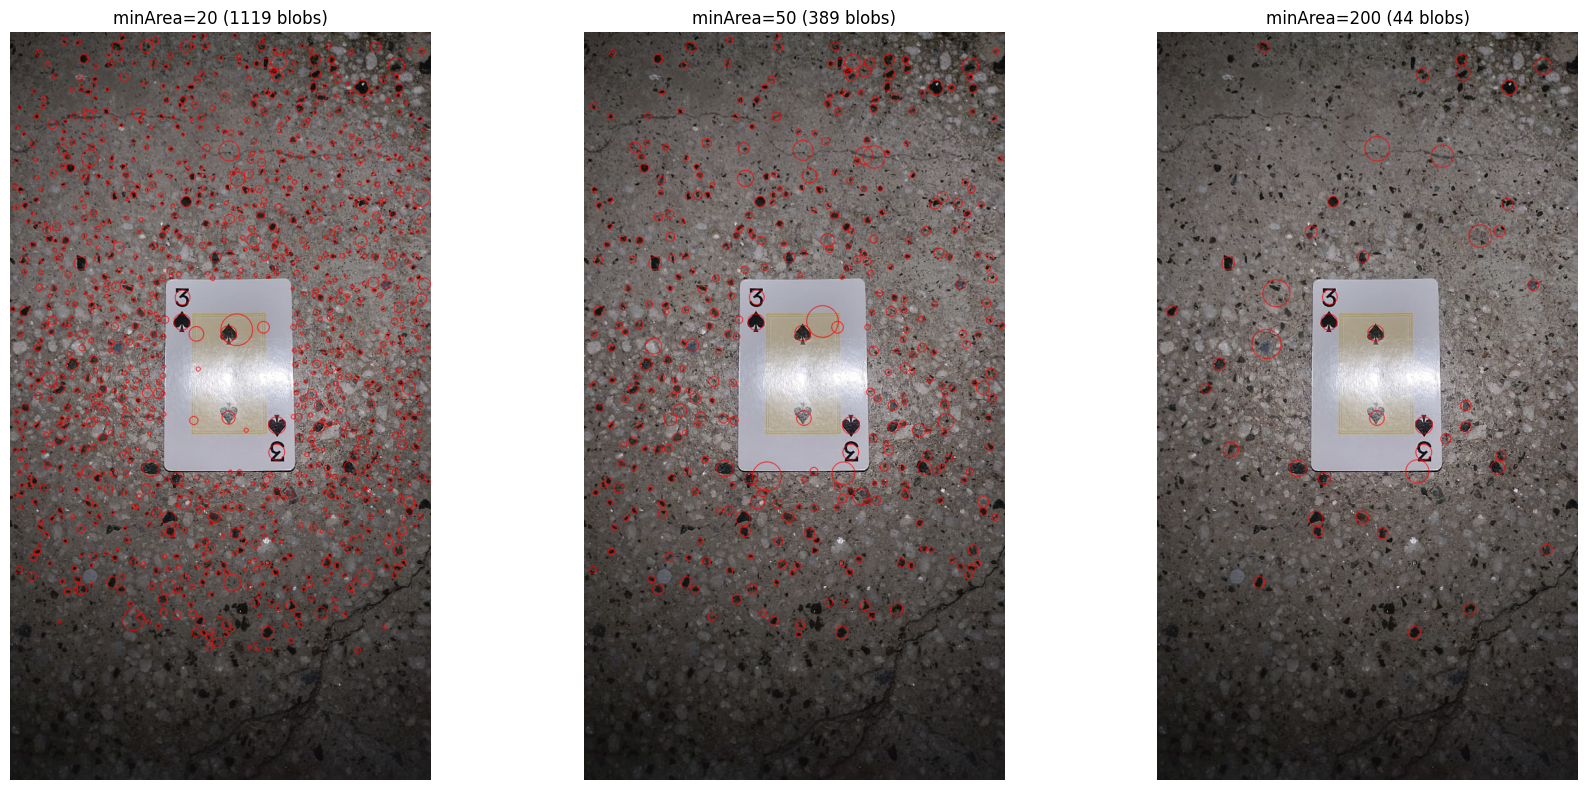

In [ ]:
img = cv.imread("carta1.jpeg", cv.IMREAD_COLOR_RGB)
gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)

# Parâmetros fixos (só o minArea varia)
MAX_AREA = 5000

valores_min_area = [20, 50, 200]

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, min_area in zip(axes, valores_min_area):
    params = cv.SimpleBlobDetector_Params()

    params.filterByArea = True
    params.minArea = min_area
    params.maxArea = MAX_AREA

    params.filterByCircularity = False
    params.filterByConvexity = False
    params.filterByInertia = False

    detector = cv.SimpleBlobDetector_create(params)
    keypoints = detector.detect(gray)

    img_blobs = cv.drawKeypoints(
        img,
        keypoints,
        None,
        (255, 0, 0),
        cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    ax.imshow(img_blobs)
    ax.set_title(f"minArea={min_area} ({len(keypoints)} blobs)")
    ax.axis("off")

plt.tight_layout()
plt.show()

### **Análise dos resultados: variação do `minArea` na detecção de Blobs**

Para justificar a escolha do `minArea`, testei três valores (`20`, `50` e `200`), mantendo fixos `maxArea=5000` e os filtros de circularidade, convexidade e inércia desativados. Assim, qualquer diferença entre as imagens vem apenas do tamanho mínimo aceito. O objetivo aqui foi diferente do restante do trabalho: selecionei a `Carta 1` justamente para observar se os **pequenos pontos escuros do piso** (pedrinhas e manchas) seriam detectados como blobs. Foi comentado em aula que esse método é utilizado para encontrar estrelas em imagens de telescópio, e fiquei interessado em ver como ele se comportaria em uma imagem com muitos pontos pequenos e dispersos. O critério que usei foi: **detectar o maior número possível de pontos pequenos do piso**.

* **`minArea=20` (1119 blobs):** Foi o valor mais permissivo. O piso ficou completamente tomado por círculos, já que até as pedrinhas e manchas menores passaram pelo filtro, o que atende ao objetivo da análise. Os naipes também foram detectados, junto com alguns outros blobs sobre a carta que não apontam nada de relevante. Com tantas marcações, a leitura visual fica difícil, mas os pequenos pontos que eu queria observar foram detectados.

* **`minArea=50` (389 blobs):** A quantidade caiu para cerca de um terço da anterior. Os naipes continuam detectados, tanto o central superior quanto o inferior, e o piso ficou menos poluído, mas isso significa que parte dos pontos pequenos foi descartada. Há também alguns círculos maiores perto da carta, que parecem juntar regiões escuras vizinhas. O resultado é mais legível que o anterior, mas já perdeu parte do que eu queria observar.

* **`minArea=200` (44 blobs):** Esse valor limpou o piso, restando apenas as manchas escuras maiores. Os pequenos pontos, que eram o foco da análise, deixaram de ser detectados, e os naipes da carta também deixaram de aparecer marcados, porque a área deles é menor que o limite. Foi rígido demais para o objetivo.

* **Melhor valor:** **20**. Foi o único que detectou os pontos menores do piso, que eram o objetivo da análise. O custo foi o excesso de marcações, com mais de mil blobs e alguns pontos sem relevância sobre a carta. Como o 20 foi o menor valor testado, é possível que um `minArea` ainda menor detecte mais pontos, mas isso não foi testado.

* **Comparação:** Aqui, o fundo dominar a contagem era o resultado esperado, já que os pontos do piso eram o alvo da análise. O comportamento lembra o uso do método em imagens de telescópio, em que pontos pequenos e isolados são destacados sobre um fundo uniforme. A diferença é que o piso é denso e irregular, com pedrinhas próximas umas das outras, então alguns pontos acabam se juntando em círculos maiores. Também ficou claro que o método não sabe o que é objeto: ele detecta naipes e pedrinhas pelo mesmo critério de tamanho, o que o torna pouco útil para localizar a carta, e isso reforça o que já havia aparecido nas estatísticas, nos histogramas e no Shi-Tomasi do cubo, em que o fundo pesa tanto quanto o objeto. Acredito que ativar o filtro de circularidade ou suavizar a imagem antes da detecção ajudaria a manter só os pontos mais arredondados, como as estrelas, mas isso não foi testado.

## 3.2 Descritores locais

Mesma classe: Cubo 2 x Cubo 3
  Imagem A: 500 keypoints
  Imagem B: 500 keypoints
  Média: 500.0



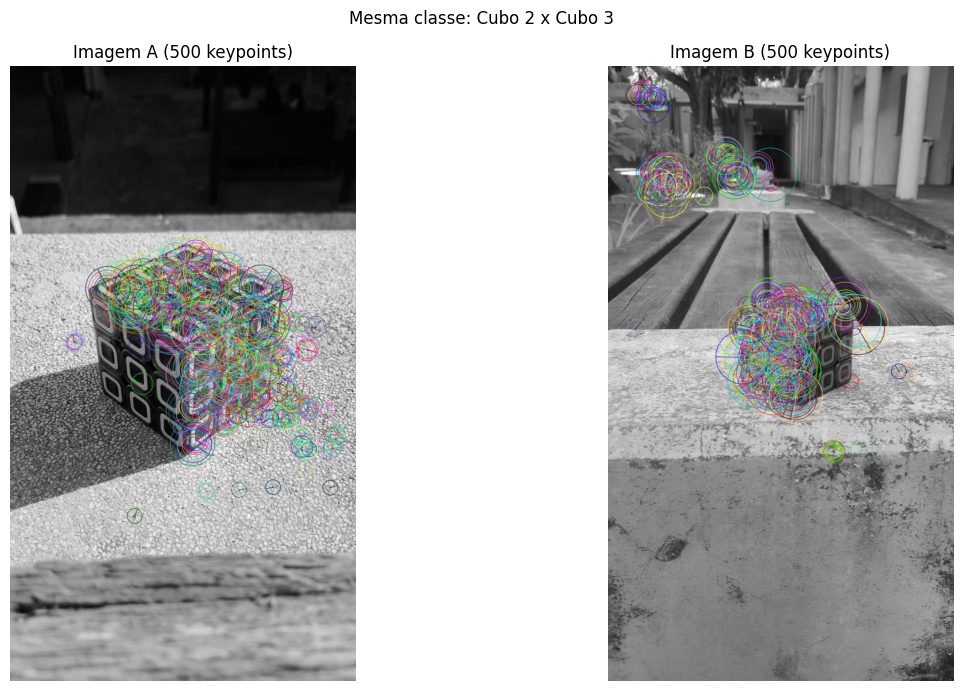

Mesma classe: Carta 4 x Carta 1
  Imagem A: 500 keypoints
  Imagem B: 500 keypoints
  Média: 500.0



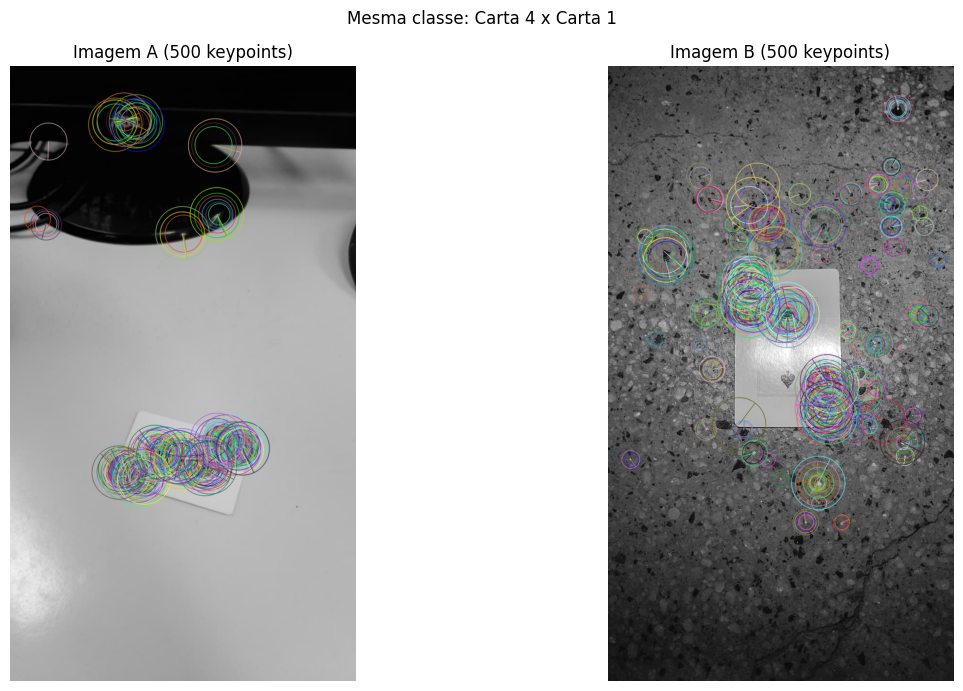

Classes diferentes: Cubo 2 x Carta 1
  Imagem A: 500 keypoints
  Imagem B: 500 keypoints
  Média: 500.0



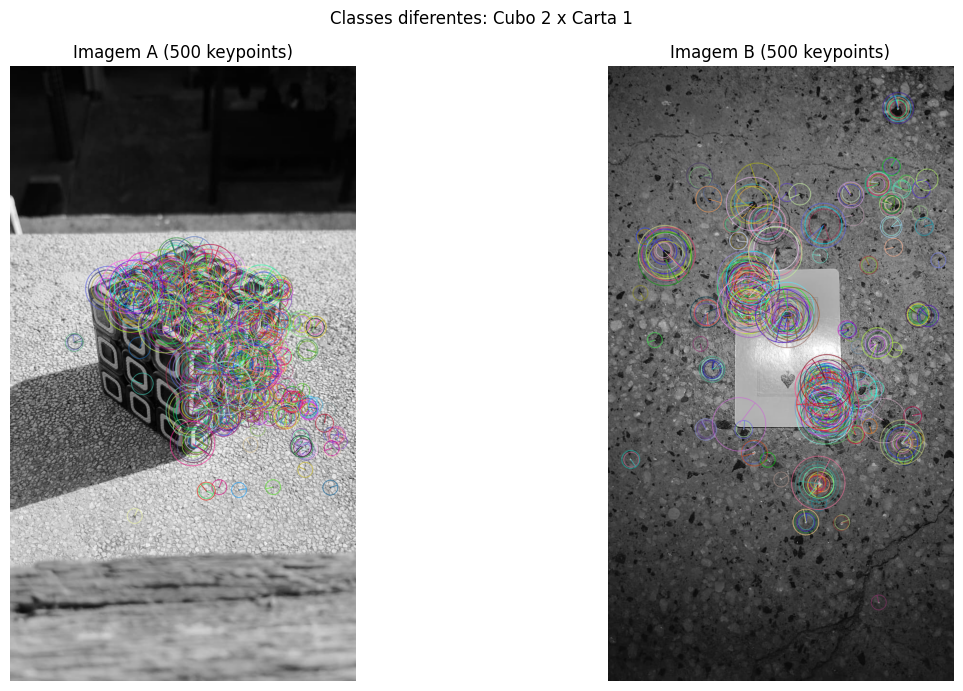

In [ ]:
# Lógica apresentada pelo professor Matheus em sala (ORB_create, função orb_features
# e show_kp), adaptada ao meu dataset

orb = cv.ORB_create(500)

def orb_features(img_or_path):
    # Se já for um array do numpy (imagem carregada), usamos diretamente
    if isinstance(img_or_path, np.ndarray):
        img = img_or_path
        # Se a imagem tiver 3 canais (colorida), convertemos para escala de cinza
        if len(img.shape) == 3:
            img = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
    else:
        # Caso contrário, lê do caminho do arquivo
        img = cv.imread(img_or_path, 0)

    kp, des = orb.detectAndCompute(img, None)
    return img, kp, des

def show_pair(a, b, title):
    img1, kp1, des1 = orb_features(a)
    img2, kp2, des2 = orb_features(b)

    # Print dos keypoints de cada imagem e da média do par
    print(f"{title}")
    # Como 'a' e 'b' podem ser arrays, mostramos seu tipo ou formato em vez do nome se não for string
    nome_a = a if isinstance(a, str) else "Imagem A"
    nome_b = b if isinstance(b, str) else "Imagem B"
    print(f"  {nome_a}: {len(kp1)} keypoints")
    print(f"  {nome_b}: {len(kp2)} keypoints")
    print(f"  Média: {(len(kp1) + len(kp2)) / 2:.1f}\n")

    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    for ax_i, img, kp, nome in [(ax[0], img1, kp1, nome_a), (ax[1], img2, kp2, nome_b)]:
        vis = cv.drawKeypoints(img, kp, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        ax_i.imshow(vis, cmap="gray")
        ax_i.set_title(f"{nome} ({len(kp)} keypoints)")
        ax_i.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_pair(imgs_A[1], imgs_A[2], "Mesma classe: Cubo 2 x Cubo 3")
show_pair(imgs_B[3], imgs_B[0], "Mesma classe: Carta 4 x Carta 1")
show_pair(imgs_A[1], imgs_B[0], "Classes diferentes: Cubo 2 x Carta 1")

### Análise dos resultados

| Comparação | Imagem 1 | Keypoints | Imagem 2 | Keypoints | Média |
|---|---|---:|---|---:|---:|
| Mesma classe (cubo) | Cubo 2 | 500 | Cubo 3 | 500 | 500.0 |
| Mesma classe (carta) | Carta 4 | 500 | Carta 1 | 500 | 500.0 |
| Classes diferentes | Cubo 2 | 500 | Carta 1 | 500 | 500.0 |

___

* Os keypoints e descritores foram extraídos com o `ORB_create(500)`, seguindo a lógica apresentada pelo professor Matheus em sala. As imagens foram lidas diretamente em escala de cinza, e cada keypoint possui um descritor de 256 bits. Foram escolhidos dois pares da mesma classe (`Cubo 2` e `Cubo 3`, `Carta 4` e `Carta 1`) e um par de classes diferentes (`Cubo 2` e `Carta 1`). Selecionei os pares da mesma classe pela similaridade visual entre as imagens. Na carta, trata-se do mesmo objeto (o 3 de espadas), apenas posicionado em outro ambiente e em outro ângulo. No cubo, também é o mesmo objeto em ambientes diferentes, e a única mudança além do fundo foi o lado do cubo que aparece em cada foto. Para o par de classes diferentes, optei por reaproveitar imagens já selecionadas nos outros pares, o `Cubo 2` e a `Carta 1`. Assim, as diferenças nos resultados vêm principalmente da aquisição (fundo, iluminação e ângulo) e, no caso do cubo, também da face exibida, e não de objetos diferentes.

* **Mesma classe, cubo (`Cubo 2` e `Cubo 3`):** Nas duas imagens, o maior aglomerado de pontos está sobre o cubo, principalmente nas bordas dos quadrados e nas faces superiores, que têm alto contraste. Os círculos são grandes e se sobrepõem bastante, o que indica que muitos pontos foram detectados em escalas maiores da pirâmide do ORB. No `Cubo 2`, há também alguns pontos soltos no chão de brita à direita e abaixo do cubo, mas a sombra, a área escura do topo e a madeira na parte inferior quase não geraram pontos. No `Cubo 3`, o resultado é diferente: além do cubo, existem dois aglomerados no fundo, na parte superior esquerda (vegetação) e na região central do topo. O concreto e o banco, que ocupam a maior parte da imagem, praticamente não receberam pontos. Ou seja, nas duas imagens o objeto concentra a maior parte dos keypoints, mas o `Cubo 3` tem uma parcela maior no fundo.

* **Mesma classe, carta (`Carta 4` e `Carta 1`):** As duas imagens mostram a mesma carta (3 de espadas), mas o resultado foi bem diferente por causa do fundo. Na `Carta 4`, os pontos se dividem em dois grupos: um sobre a carta, bem concentrado, e outro no monitor, no topo, que tem alto contraste entre preto e cinza. A mesa branca, que ocupa quase todo o restante da imagem, não recebeu pontos, já que é uma região homogênea. Como o fundo quase não gera pontos, os 500 acabaram amontoados na carta e no monitor, com muitos círculos sobrepostos. Na `Carta 1`, os pontos estão espalhados por todo o piso, pois cada pedrinha e mancha gera um canto, e a carta aparece em meio a eles, com aglomerados perto do número e do naipe de cada canto. A parte inferior da imagem, que é bem escura, quase não recebeu pontos. Nesse caso, o fundo competiu diretamente com a carta pelos 500 pontos disponíveis.

* **Classes diferentes (`Cubo 2` e `Carta 1`):** Aqui as imagens são as mesmas dos pares anteriores, então a distribuição dos pontos é a já descrita. O cubo concentra os pontos no objeto, enquanto a carta divide os pontos entre o objeto e o piso. Isso reforça o que já havia aparecido nos outros métodos: o fundo pode ter peso tão grande quanto o objeto. Como as duas imagens bateram no limite, a quantidade de pontos não ajuda a diferenciar as classes, e a qualidade só pode ser avaliada no matching, com os descritores.

## 3.3 Matching utilizando BF-Matcher

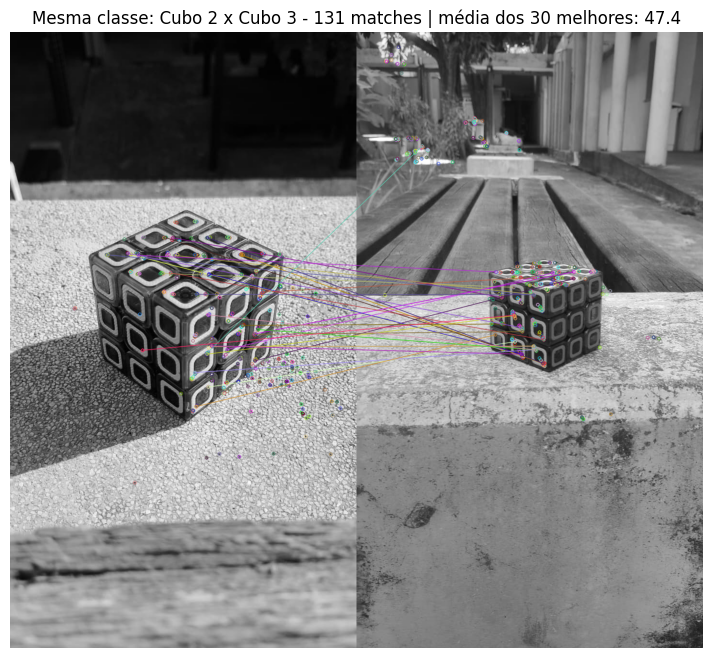

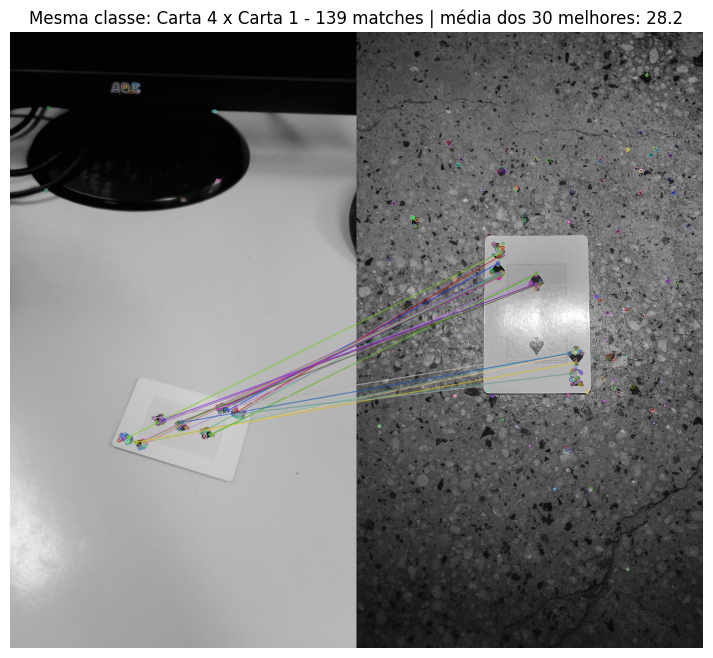

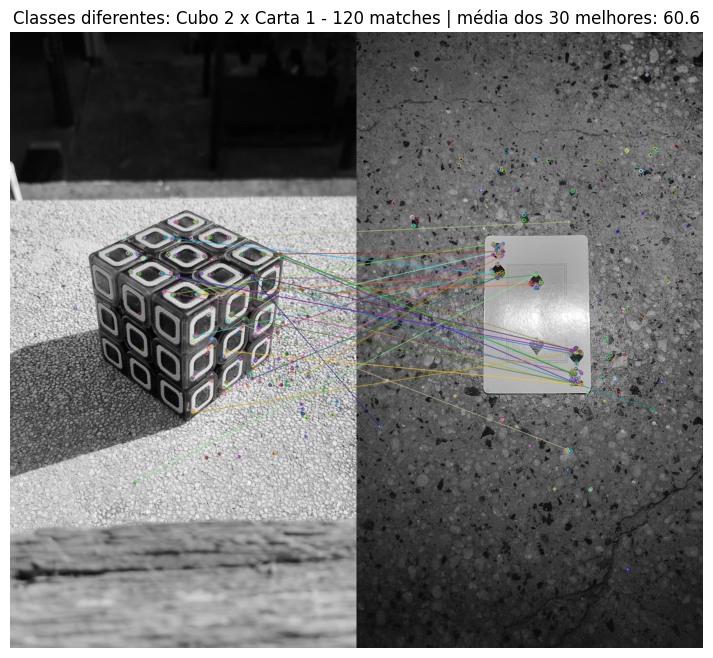

In [ ]:
# Lógica apresentada pelo professor Matheus em sala
bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)

def match_pair(a, b, title):
    img1, kp1, des1 = orb_features(a)
    img2, kp2, des2 = orb_features(b)

    matches = sorted(bf.match(des1, des2), key=lambda x: x.distance)  # menor distância = melhor
    dist_top = np.mean([m.distance for m in matches[:30]])

    img_match = cv.drawMatches(img1, kp1, img2, kp2, matches[:30], None)

    plt.figure(figsize=(16, 8))
    plt.imshow(img_match, cmap="gray")
    plt.title(f"{title} - {len(matches)} matches | média dos 30 melhores: {dist_top:.1f}")
    plt.axis("off")
    plt.show()

for a, b, title in [(imgs_A[1], imgs_A[2], "Mesma classe: Cubo 2 x Cubo 3"),
                    (imgs_B[3], imgs_B[0], "Mesma classe: Carta 4 x Carta 1"),
                    (imgs_A[1], imgs_B[0], "Classes diferentes: Cubo 2 x Carta 1")]:
    match_pair(a, b, title)

### **Resultados a serem exibidos:**
As figuras acima exibem os 30 melhores matches de cada par, ordenados pela menor distância de Hamming. O `BFMatcher` usou `NORM_HAMMING` com `crossCheck=True`, seguindo a lógica apresentada pelo professor Matheus em sala. Os pares são os mesmos da seção 3.2: nos dois pares da mesma classe, o objeto é o mesmo em ambientes diferentes (no cubo, muda também o lado exibido), e o par de classes diferentes reaproveita imagens já selecionadas.

| Comparação | Imagens | Total de matches | Distância média dos 30 melhores |
|---|---|---:|---:|
| Mesma classe (cubo) | Cubo 2 x Cubo 3 | 143 | 47.8 |
| Mesma classe (carta) | Carta 4 x Carta 1 | 140 | 28.4 |
| Classes diferentes | Cubo 2 x Carta 1 | 115 | 60.5 |

---

### **Análise e Discussão:**
* **Houve mais correspondências úteis entre imagens da mesma classe?**
  * *Resposta:* Sim, mas com uma diferença entre os dois pares. Os pares da mesma classe tiveram mais matches (143 e 140 contra 115) e distâncias menores (47.8 e 28.4 contra 60.5). O melhor resultado foi o da `Carta 4` com a `Carta 1`: as linhas ligam os símbolos de uma carta aos símbolos da outra, principalmente o número e os naipes dos cantos, e a distância média foi a menor de todas. Perceba, porém, que as duas imagens mostram a mesma carta (3 de espadas), então esse resultado se deve ao objeto ser o mesmo, e não só à classe. No par dos cubos, o objeto também é o mesmo, mas cada foto mostra um lado diferente do cubo, então as duas imagens têm poucas regiões realmente em comum. Por isso o resultado é menos confiável, já que o cubo é formado por uma grade de quadrados idênticos. Qualquer quadrado de uma face pode ser confundido com qualquer outro, e várias linhas se cruzam, o que sugere que muitos matches ligam quadrados parecidos, e não o mesmo ponto do cubo. Já no par de classes diferentes, as linhas saem das bordas dos quadrados do cubo e vão para os naipes da carta, mas também para pontos soltos do piso, sem relação visível entre as regiões. Ou seja, houve mais correspondências úteis dentro da mesma classe, e essa diferença é clara nas cartas e mais discutível nos cubos.

* **A quantidade de matches significou qualidade?**
  * *Resposta:* Não. O par de classes diferentes teve 115 matches, apenas cerca de 20% a menos que os pares da mesma classe, mesmo com imagens que não têm nada em comum. O par dos cubos reforça isso: ele teve 143 matches, o maior total, mesmo com as imagens mostrando lados diferentes do cubo. O `crossCheck=True` só exige que os dois descritores se escolham mutuamente, e isso não garante que a correspondência esteja certa. Por isso um match pode existir e ainda assim ligar regiões sem relação. A distância média dos 30 melhores foi um indicador bem melhor do que a quantidade: 28.4 na carta, 47.8 no cubo e 60.5 no par misto, na mesma ordem do que se vê nas figuras. Mesmo assim, a distância não é uma garantia, já que o par dos cubos teve distância intermediária e ainda mostra linhas ambíguas. Também vale lembrar que as imagens bateram no limite de 500 keypoints, então os totais de matches não representam tudo o que as imagens poderiam gerar. Acredito que a forma mais objetiva de medir a qualidade seria contar quantos matches sobrevivem a uma verificação geométrica, como o RANSAC, mas isso não foi testado.

* **Fatores como iluminação, escala, fundo ou ângulo atrapalharam o matching?**
  * *Resposta:* Sim, em graus diferentes. A **escala** foi o fator mais evidente no par dos cubos: no `Cubo 2` o cubo ocupa boa parte da imagem, enquanto no `Cubo 3` ele é bem menor, então as mesmas regiões são descritas em tamanhos diferentes, o que dificulta a comparação. Alguns matches do `Cubo 3` também foram para o fundo, na parte superior da imagem. O **ângulo** também pesou, e no cubo de forma mais forte: como ele é tridimensional, o lado exibido muda de uma foto para a outra, e as faces visíveis deixam de coincidir. Já na carta, que é plana, a rotação foi bem tolerada, já que o ORB calcula a orientação de cada ponto. A **iluminação** foi bem diferente entre a `Carta 4` (mesa clara) e a `Carta 1` (piso escuro, com vinheta), e mesmo assim os símbolos foram ligados. Acredito que isso ocorre porque o descritor compara intensidades entre pixels vizinhos, e essas relações se mantêm quando o brilho muda. Quanto ao **fundo**, o monitor da `Carta 4` e o piso da `Carta 1` geraram muitos keypoints sem correspondente na outra imagem, mas eles não apareceram entre os 30 melhores matches, que ficaram todos sobre as cartas. No par de classes diferentes, o fundo foi o que mais atrapalhou, já que parte das linhas termina no piso. De modo geral, isso reforça a conclusão do trabalho: o resultado depende tanto do fundo e da aquisição quanto do objeto.

# **Parte 4** - Análise de textura: GLCM e LBP

## 4.1 Seleção das regiões
* Selecionei um recorte de cada classe de maneira direta usando a ferramenta de ajuste do meu celular e adicionei dentro de uma classe presente no meu dataset que serve para armazenar imagens extras. As imagens geradas foram `cubo2_aproximado.jpeg` e `carta4_aproximada.jpeg`. Tentei recortar de uma forma que os objetos ficassem mais destacados na imagem, mas que o fundo ainda aparecesse um pouco. Fiz isso para que a textura do fundo também fosse incorporada na análise.

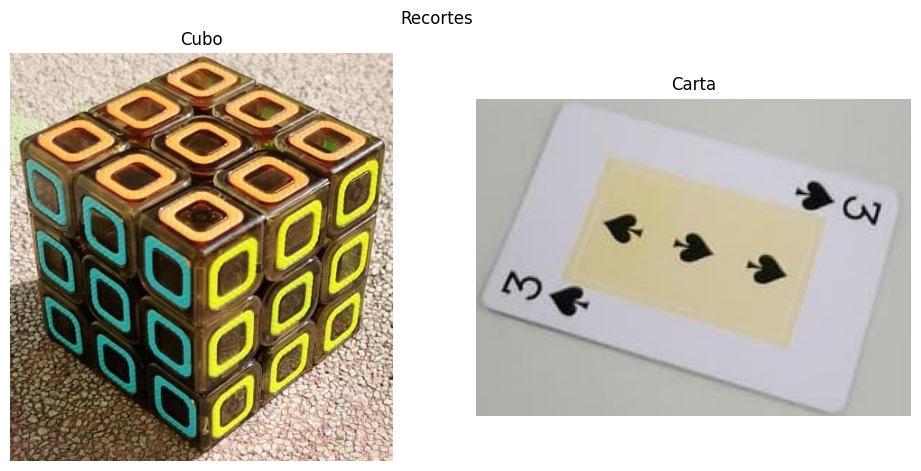

In [ ]:
# Visualização dos recortes feitos

cubo = cv.cvtColor(cv.imread("cubo2_aproximado.jpeg"), cv.COLOR_BGR2RGB)
carta = cv.cvtColor(cv.imread("carta4_aproximada.jpeg"), cv.COLOR_BGR2RGB)

imgs = [[cubo, carta]]
nomes = [['Cubo', 'Carta']]

fig, ax = vision.criar_figure('Recortes', 1, 2, fig_size=(10, 5))
vision.preencher_figure(ax, imgs)
vision.nomear_axes(ax, nomes)
vision.remover_axis(ax.flatten())
plt.show()

## 4.2 GLCM

In [ ]:
# Lógica apresentada pelo professor Matheus em sala (graycomatrix e graycoprops)

# Conversão para cinza e quantização de 256 para 8 níveis (0 a 7)
cubo_q = cv.cvtColor(cubo, cv.COLOR_RGB2GRAY) // 32
carta_q = cv.cvtColor(carta, cv.COLOR_RGB2GRAY) // 32

angulos = [0, np.pi / 4]  # 0° e 45°
props = ["contrast", "homogeneity", "energy", "correlation"]

linhas = []
for nome, img_q in [("Cubo", cubo_q), ("Carta", carta_q)]:
    glcm = sk.feature.graycomatrix(img_q, distances=[1], angles=angulos,
                                   levels=8, symmetric=True, normed=True)

    for i, ang in enumerate(["0°", "45°"]):
        linhas.append({"Imagem": nome, "Distância": 1, "Ângulo": ang,
                       **{p: sk.feature.graycoprops(glcm, p)[0, i] for p in props}})

tabela = pd.DataFrame(linhas)
print(tabela.round(4).to_string(index=False))

Imagem  Distância Ângulo  contrast  homogeneity  energy  correlation
  Cubo          1     0°    0.5629       0.8026  0.2750       0.9420
  Cubo          1    45°    0.9650       0.7454  0.2542       0.9005
 Carta          1     0°    0.1012       0.9702  0.6517       0.9470
 Carta          1    45°    0.1857       0.9577  0.6396       0.9032


### **Resultados GLCM (Tabela Resumo)**

| Classe | Patch / Imagem | Distância | Ângulo | Contraste | Homogeneidade | Energia | Correlação |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **A** | Cubo (recorte) | 1 | 0° | 0.5629 | 0.8026 | 0.2750 | 0.9420 |
| **A** | Cubo (recorte) | 1 | 45° | 0.9650 | 0.7454 | 0.2542 | 0.9005 |
| **B** | Carta (recorte) | 1 | 0° | 0.1012 | 0.9702 | 0.6517 | 0.9470 |
| **B** | Carta (recorte) | 1 | 45° | 0.1857 | 0.9577 | 0.6396 | 0.9032 |

*Discussão técnica sobre as propriedades extraídas:*

A GLCM foi calculada com distância de 1 pixel e ângulos de 0° e 45°, após converter os recortes para cinza e quantizá-los para 8 níveis. Os recortes foram o `cubo2_aproximado.jpeg` e o `carta4_aproximada.jpeg`.

* **Contraste:** Foi a propriedade que mais separou as classes. O cubo teve contraste de 0.5629 em 0° e 0.9650 em 45°, cerca de cinco vezes maior que o da carta (0.1012 e 0.1857). Isso já era esperado, porque o cubo é formado por uma grade de quadrados claros com bordas pretas, e a cada transição os pixels vizinhos mudam bastante de nível. A carta, por outro lado, tem uma superfície branca e contínua, com poucas transições entre vizinhos.

* **Homogeneidade:** Segue o inverso do contraste. A carta teve valores próximos de 1 (0.9702 e 0.9577), o que indica que quase todos os pixels vizinhos têm níveis parecidos. O cubo ficou mais baixo (0.8026 e 0.7454), o que reflete a quantidade maior de bordas. Ainda assim, o cubo não ficou tão baixo quanto eu esperava, o que sugere que boa parte do recorte é formada por regiões lisas (as faces dos quadrados), e as bordas ocupam uma parcela menor da área.

* **Energia:** A carta teve energia de 0.6517 e 0.6396, mais de duas vezes maior que a do cubo (0.2750 e 0.2542). Isso mostra que a matriz da carta está concentrada em poucos pares de níveis (basicamente os tons claros do papel), enquanto no cubo os pares de níveis se espalham mais, por causa da mistura de preto, branco e tons intermediários.

* **Correlação:** Foi a propriedade que menos separou as classes. Os valores ficaram altos e muito próximos nos dois recortes, entre 0.90 e 0.95. Isso indica que, em ambos, o nível de um pixel prediz bem o nível do vizinho, o que é típico de superfícies lisas e de transições suaves. Como a correlação mede dependência linear e não a quantidade de variação, ela não captou a diferença de contraste entre as duas imagens.

* **Efeito do ângulo:** Nos dois recortes, o contraste aumentou de 0° para 45° (de 0.5629 para 0.9650 no cubo e de 0.1012 para 0.1857 na carta), e a homogeneidade, a energia e a correlação caíram levemente. Parte disso pode vir de a direção diagonal comparar pixels mais distantes (cerca de 1,41 pixel), o que favorece diferenças maiores. O cubo teve uma variação mais forte, o que pode estar ligado à orientação das bordas dos quadrados, mas isso é uma hipótese, e não foi testada com outros ângulos.

* **Limitação:** Tanto o cubo quanto a carta têm superfícies lisas, sem textura de material (como tecido ou madeira). Por isso, os recortes carregam principalmente bordas e símbolos, e não uma textura própria da superfície. A GLCM captou, na prática, a diferença de estrutura visual (grade contra superfície lisa). Além disso, a quantização em 8 níveis e a distância de 1 pixel dependem da resolução dos recortes, e uma resolução diferente poderia mudar os valores.

* **Conclusão parcial:** Contraste, homogeneidade e energia diferenciaram bem as classes, com o cubo mais contrastado e a carta mais homogênea e uniforme, enquanto a correlação foi parecida nas duas. Essa diferença é coerente com o que foi previsto na seção 1.3 (grade de alto contraste no cubo e superfície mais lisa na carta).

## 4.3 LBP


Cubo [0.0525 0.0761 0.061  0.1204 0.238  0.1241 0.0703 0.0774 0.0688 0.1114]
Carta [0.0106 0.0242 0.0078 0.0419 0.0874 0.1698 0.0323 0.0429 0.5465 0.0365]


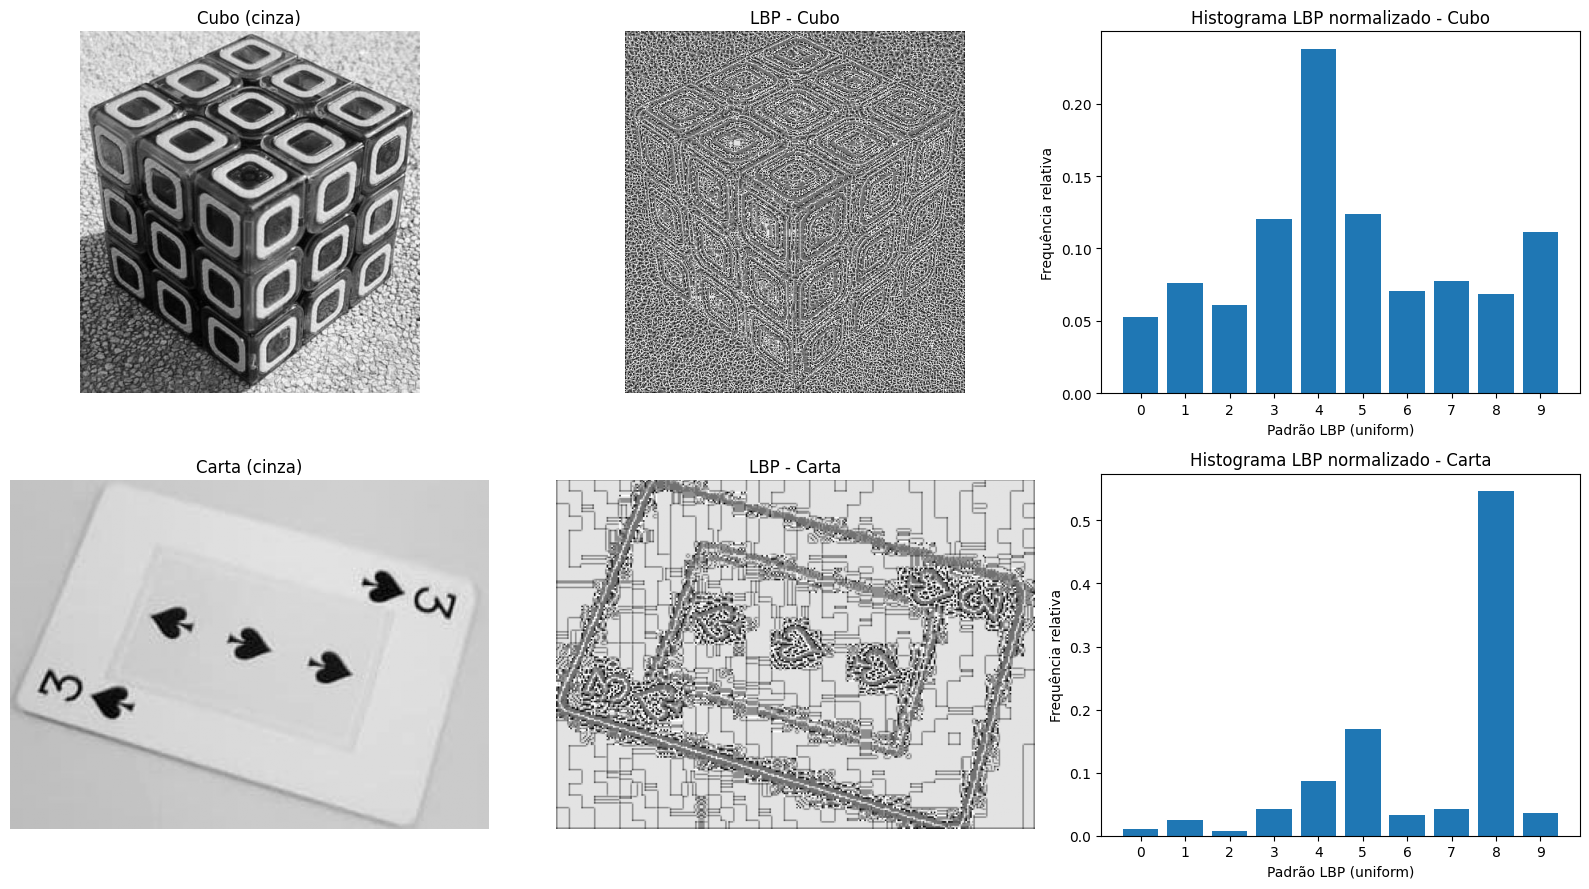

In [ ]:
# Lógica apresentada pelo professor Matheus em sala (local_binary_pattern com
# 8 vizinhos, raio 1 e method="uniform")

cubo_gray = cv.cvtColor(cubo, cv.COLOR_RGB2GRAY)
carta_gray = cv.cvtColor(carta, cv.COLOR_RGB2GRAY)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

for linha, (nome, img) in enumerate([("Cubo", cubo_gray), ("Carta", carta_gray)]):
    lbp = sk.feature.local_binary_pattern(img, 8, 1, method="uniform")

    # Histograma normalizado: 10 padrões (0 a 9), soma = 1
    hist = np.bincount(lbp.astype(int).ravel(), minlength=10) / lbp.size
    print(nome, hist.round(4))

    ax[linha, 0].imshow(img, cmap="gray")
    ax[linha, 0].set_title(f"{nome} (cinza)")
    ax[linha, 0].axis("off")

    ax[linha, 1].imshow(lbp, cmap="gray")
    ax[linha, 1].set_title(f"LBP - {nome}")
    ax[linha, 1].axis("off")

    ax[linha, 2].bar(range(10), hist)
    ax[linha, 2].set_title(f"Histograma LBP normalizado - {nome}")
    ax[linha, 2].set_xticks(range(10))
    ax[linha, 2].set_xlabel("Padrão LBP (uniform)")
    ax[linha, 2].set_ylabel("Frequência relativa")

plt.tight_layout()
plt.show()

### **Análise e Discussão de Textura:**
O LBP foi calculado com 8 vizinhos, raio 1 e `method="uniform"`, sobre os recortes em cinza (`cubo2_aproximado.jpeg` e `carta4_aproximada.jpeg`). O histograma normalizado tem 10 padrões: de 0 a 8 são os uniformes, e o 9 agrupa todos os não uniformes. Os valores analisados abaixo vêm do vetor exato impresso pelo código.

* **O LBP capturou microestruturas visuais úteis?**
  * *Resposta:* Sim, nos dois recortes, mas de formas bem diferentes. No cubo, o mapa LBP desenhou o contorno dos quadrados e das faces, mostrando as bordas entre as partes claras e escuras. O histograma ficou espalhado entre vários padrões, com pico no padrão 4 (0.2380) e os padrões 3 e 5 em torno de 0.12 (0.1204 e 0.1241, respectivamente). Esses padrões intermediários correspondem a bordas e transições, o que combina com a grade de quadrados. O padrão 9 (não uniforme) ficou em 0.1114, indicando microestruturas mais irregulares. Perceba também que o mapa do cubo é bem ruidoso na região do fundo, pois o chão de brita gera muita variação local, então parte do que o LBP capturou é textura do fundo e não do objeto. Na carta, o mapa mostra com nitidez o contorno da carta, o retângulo interno e os naipes, que aparecem como regiões cheias de pontos pretos e brancos, ou seja, padrões não uniformes. O resto da carta é uma região lisa, e o padrão 8 sozinho ocupa 0.5465 do histograma, com o padrão 5 em segundo (0.1698). Os blocos retangulares visíveis nas áreas planas da carta sugerem que a imagem tem pouca variação real nessas regiões, e acredito que isso venha de suavização ou de compressão do recorte, mas isso não foi testado. Ou seja, o LBP captou o que existe de estrutura em cada recorte, mas como as superfícies são lisas, o que ele descreveu foram principalmente bordas e símbolos, e não uma textura própria do material.

* **As classes ficaram mais separáveis por textura?**
  * *Resposta:* Sim, para esses dois recortes. Os histogramas são bem diferentes: o da carta é dominado por um único padrão (8), enquanto o do cubo distribui as frequências entre vários padrões, sem nenhum acima de 0.25. Isso é uma separação bem mais clara do que a obtida com os histogramas globais de intensidade, em que, como discuti na seção 2.2, as classes não ficaram separadas por causa do fundo. Acredito que a diferença venha de os recortes terem reduzido o fundo, que ainda aparece um pouco nos recortes, de modo que a análise passou a se concentrar na superfície do objeto. Ainda assim, essa conclusão tem alcance limitado: foi usado apenas um recorte por classe, feito manualmente, e o resultado depende de quanto da carta é superfície lisa e de quanto do chão entrou no recorte do cubo. Além disso, o LBP com raio 1 depende da resolução, e um recorte com outro tamanho ou outra escala poderia mudar os histogramas. Por isso, a separação aqui é uma evidência a favor, mas não uma prova.

* **GLCM e LBP trouxeram evidências coerentes entre si?**
  * *Resposta:* Sim. A GLCM mostrou que o cubo tem contraste bem maior (0.56 a 0.97 contra 0.10 a 0.19 da carta), homogeneidade menor (0.75 a 0.80 contra 0.96 a 0.97) e energia menor (0.25 a 0.27 contra 0.64 a 0.65). O LBP conta a mesma história por outro caminho: a carta concentra mais da metade dos pixels em um padrão (região plana), o que combina com a homogeneidade e a energia altas, enquanto o cubo espalha os pixels entre vários padrões, o que combina com o contraste alto e a energia baixa. A correlação da GLCM foi parecida nos dois recortes (0.90 a 0.95), e o LBP não tem uma medida equivalente, então ela não pode ser comparada diretamente. Vale lembrar também que os dois descritores medem coisas diferentes. A GLCM mede a intensidade das diferenças entre vizinhos (por exemplo, o contraste), enquanto o LBP só registra se o vizinho é maior ou menor que o centro, sem considerar o tamanho da diferença. Por isso, o LBP descreve a estrutura local, e a GLCM, a intensidade das transições. Mesmo assim, os dois apontaram para a mesma conclusão: o cubo é mais estruturado e irregular, e a carta é mais lisa e uniforme.

# **Parte 5** - Síntese integradora

## 5.1 Tabela comparativa final

| Tipo de descritor | O que representa | Vantagens | Limitações | Funcionou bem no meu dataset? |
| :--- | :--- | :--- | :--- | :--- |
| **Histogramas** | A distribuição dos níveis de intensidade (em cinza) ou de cada canal RGB, sem informar a posição dos pixels. | Simples e barato. Mostra brilho, contraste e canais dominantes, e manteve a forma mesmo após a quantização para 64 níveis. | Reflete a imagem inteira, então o fundo e a iluminação dominam. Não diz onde estão os pixels nem o que é o objeto. | **Parcialmente.** Descreveu bem a aquisição (piso escuro, mesa branca, monitor), mas não separou as classes. |
| **Estatística global** | Média, variância, desvio padrão e entropia calculados sobre todos os valores da imagem (RGB, três canais juntos). | Rápida, compacta (4 números) e fácil de interpretar. Resume brilho, contraste e diversidade de níveis. | Dominada pelo fundo. A diferença entre as classes foi pequena (média de 125.80 contra 132.92 e variância de 3211.76 contra 3002.91). No RGB, mistura contraste de brilho com diversidade de cores. | **Pouco.** Descreveu cada foto, mas não diferenciou cubo de carta. A entropia foi a que mais diferenciou (7.14 contra 6.60), com exceções. |
| **ORB + matching** | Cantos da imagem (keypoints) com um descritor binário de 256 bits da vizinhança, comparados pela distância de Hamming. | Tolera rotação e mudança de iluminação. Reconheceu a mesma carta em ambientes diferentes (distância média de 28.4). A distância dos melhores matches indicou melhor a qualidade do que a quantidade. | Os pontos se espalham pelo fundo (piso, monitor, brita) e bateram no limite de 500. É sensível à escala e à face visível do cubo, e a grade repetitiva gera matches ambíguos. Não houve verificação geométrica. | **Parcialmente.** Bem na carta (mesmo objeto), mal no cubo (faces diferentes). O par de classes diferentes teve 115 matches, então a quantidade não indicou qualidade. |
| **GLCM** | Como os níveis de cinza (8 níveis) se repetem entre pixels vizinhos, a 1 pixel de distância e nos ângulos de 0° e 45°. | Traduz a textura em números interpretáveis. Separou as classes com folga: o contraste do cubo foi cerca de cinco vezes o da carta. | Depende dos parâmetros (níveis, distância, ângulo) e da resolução. A correlação não separou as classes. As superfícies são lisas, então captou bordas e símbolos, e não textura de material. | **Sim, com ressalva.** Funcionou nos recortes, mas só havia um recorte por classe. |
| **LBP** | Para cada pixel, compara o centro com 8 vizinhos (raio 1) e gera um histograma normalizado de 10 padrões uniformes. | Barato e gera um mapa visual das microestruturas. O histograma normalizado permite comparar imagens de tamanhos diferentes. A carta concentrou 0.55 no padrão 8, enquanto o cubo ficou espalhado (pico de 0.24). | Ignora o tamanho da diferença entre vizinhos e depende da resolução. É sensível a ruído e a compressão (brita ruidosa no cubo, blocos na carta). O histograma perde a posição. | **Sim, com ressalva.** Foi coerente com a GLCM, mas com o mesmo limite de um recorte por classe. |

---

## 5.2 Conclusões Finais

1. **Qual descritor foi mais útil no seu dataset?**
   * *Resposta:* Para separar as classes, os descritores de textura (GLCM e LBP) foram os mais úteis, e os dois apontaram a mesma conclusão. O cubo é mais irregular, com contraste de 0.56 a 0.97 contra 0.10 a 0.19 da carta e um histograma LBP espalhado entre vários padrões, sem nenhum acima de 0.25. A carta é lisa e uniforme, com homogeneidade acima de 0.95 e o padrão 8 sozinho com cerca de 0.55 do histograma. Já para reconhecer o mesmo objeto em cenários diferentes, o ORB com matching foi o mais útil: ele ligou os símbolos da mesma carta apesar da diferença de fundo e de iluminação, com a menor distância média (28.4). Perceba, porém, que essa vantagem da textura não é só do descritor. A GLCM e o LBP foram calculados em recortes que reduziram o fundo, enquanto os histogramas e as estatísticas usaram a imagem inteira. Por isso, não dá para afirmar que a textura é melhor por si só. Acredito que calcular os descritores globais nos mesmos recortes mostraria isso, mas acabei não testando.

2. **Qual descritor foi menos útil?**
   * *Resposta:* A estatística global. Média, variância, desvio padrão e entropia resumem a imagem em poucos números dominados pelo fundo, e a diferença entre as classes foi pequena (média de 125.80 contra 132.92 e variância de 3211.76 contra 3002.91). A `Carta 2`, por exemplo, teve a menor variância e entropia só porque a mesa branca ocupa quase tudo, e o `Cubo 2` teve os maiores valores por causa da sombra e da madeira, e não do cubo. Os histogramas ficaram logo acima, porque também são globais e não separaram as classes, mas ao menos mostraram onde e por que as intensidades se concentram, o que ajudou a entender cada foto.

3. **Em que situações a aquisição influenciou fortemente os resultados?**
   * *Resposta:* Em praticamente todas as etapas, e o **fundo** foi o fator mais forte. No `Cubo 2`, o chão de brita tomou os 500 pontos do Shi-Tomasi mesmo com o `qualityLevel` subindo de 0.01 para 0.2, e no piso da `Carta 1` o detector de blobs chegou a 1119 marcações. No ORB, o monitor da `Carta 4` e o piso da `Carta 1` também competiram com a carta pelos pontos. A **iluminação** pesou no estouro de luz da `Carta 2`, que atrapalhou a detecção dos naipes de baixo, e nas vinhetas e sombras do `Cubo 4`, do `Cubo 5` e da `Carta 1`, que baixaram a média e mudaram os histogramas. A **escala** e o **ângulo** pesaram no matching, já que o cubo aparece bem menor no `Cubo 3` e mostra um lado diferente em cada foto, o que deixou o par dos cubos pouco confiável. O **desfoque** do `Cubo 1`, feito de propósito, derrubou a variância e a entropia (5.83). Por fim, a **resolução** e o recorte afetaram a textura, já que a GLCM e o LBP dependem do tamanho do recorte e da distância usada.

4. **Se você fosse treinar um sistema simples de Visão Computacional com esse dataset, quais características usaria primeiro?**
   * *Resposta:* Primeiro, eu isolaria o objeto por recorte ou segmentação, porque ao longo do trabalho o fundo foi o que mais atrapalhou. Em seguida, usaria como características iniciais a textura: contraste, homogeneidade e energia da GLCM e o histograma normalizado do LBP (10 valores). Elas separaram as classes e são baratas de calcular. Depois, acrescentaria o histograma de cor e as estatísticas, mas só dentro da região do objeto, porque a hipótese da seção 1.3 (cores vivas no cubo e branco na carta) não pôde ser confirmada com a imagem inteira. O ORB com matching eu guardaria para reconhecer um objeto específico (como a mesma carta), e não para classificar. Ainda assim, essas escolhas têm alcance limitado: são só 10 imagens, um recorte por classe e nenhuma separação entre treino e teste. Além disso, a classe das cartas tem cartas diferentes, enquanto a do cubo tem um único objeto, então seria preciso testar com mais recortes e mais cartas antes de confiar no resultado.